# Craigslist Used-Car Price Prediction
## Data Preparation, Visualization, Regression, PCA, and Feature Selection

The notebook contains one continuous analysis of the Craigslist used-vehicle dataset.

**Input file:** `vehicles.csv`

In [ ]:
import pandas as pd

selected_columns = "price year odometer manufacturer condition cylinders fuel".split()
selected_columns += "title_status transmission drive size type paint_color state".split()
raw = pd.read_csv("vehicles.csv")
all_columns = raw.columns.tolist()
raw = raw[selected_columns].copy()

for column in ["price", "year", "odometer"]:
    raw[column] = pd.to_numeric(raw[column], errors="coerce")

missing_table = pd.DataFrame()
missing_table["Missing rows"] = raw.isna().sum()
missing_table["Missing percent"] = (raw.isna().mean() * 100).round(2)

print("Original rows:", len(raw))
print("Original columns:", len(all_columns))
print("Selected columns:", len(selected_columns))
display(raw[["price", "year", "odometer"]].describe().round(2))

Original rows: 426880
Original columns: 26
Selected columns: 14


,price,year,odometer
count,4.268800e+05,425675.00,422480.00
mean,7.519903e+04,2011.24,98043.33
std,1.218228e+07,9.45,213881.50
min,0.000000e+00,1900.00,0.00
25%,5.900000e+03,2008.00,37704.00
50%,1.395000e+04,2013.00,85548.00
75%,2.648575e+04,2017.00,133542.50
max,3.736929e+09,2022.00,10000000.00


In [ ]:
original_rows = len(raw)
price_low = raw["price"].quantile(0.10)
price_high = raw["price"].quantile(0.99)
price_mask = (raw["price"] > price_low) & (raw["price"] < price_high)
clean = raw[price_mask].copy()
odometer_low = clean["odometer"].quantile(0.10)
odometer_high = clean["odometer"].quantile(0.99)
odometer_mask = (clean["odometer"] > odometer_low)
odometer_mask &= clean["odometer"] < odometer_high
clean = clean[odometer_mask].copy()
clean["year"] = clean["year"].fillna(clean["year"].median())
categorical_columns = "manufacturer condition cylinders fuel title_status".split()
categorical_columns += "transmission drive size type paint_color state".split()

for column in categorical_columns:
    clean[column] = clean[column].fillna("unknown").astype(str)
    clean[column] = clean[column].str.strip().str.lower()
    category_frequency = clean[column].value_counts(normalize=True)
    clean[column + "_freq"] = clean[column].map(category_frequency)

clean["vehicle_age"] = 2022 - clean["year"]
encoded_features = [column + "_freq" for column in categorical_columns]
all_features = ["vehicle_age", "odometer"] + encoded_features
baseline_removed = ["paint_color_freq", "state_freq"]
baseline_features = [item for item in all_features if item not in baseline_removed]
clean_rows = len(clean)
removed_rows = original_rows - clean_rows
cleaning_summary = pd.DataFrame()
cleaning_summary["Item"] = ["Original rows", "Rows after cleaning", "Rows removed"]
cleaning_summary["Value"] = [original_rows, clean_rows, removed_rows]

print("Price limits:", price_low, price_high)
print("Odometer limits:", odometer_low, odometer_high)
print("Rows after cleaning:", clean_rows)
print("Baseline input features:", len(baseline_features))
print("Full input features:", len(all_features))
display(clean[["price", "year", "vehicle_age", "odometer"]].describe().round(2))

Price limits: 500.0 66995.0
Odometer limits: 15812.0 280000.0
Rows after cleaning: 335851
Baseline input features: 11
Full input features: 13


,price,year,vehicle_age,odometer
count,335851.00,335851.00,335851.00,335851.00
mean,17534.84,2010.76,11.24,101335.80
std,12645.53,8.46,8.46,56884.39
min,501.00,1900.00,0.00,15813.00
25%,7425.50,2008.00,6.00,53000.00
50%,14500.00,2013.00,9.00,96936.00
75%,25226.50,2016.00,14.00,140337.00
max,66992.00,2022.00,122.00,279974.00


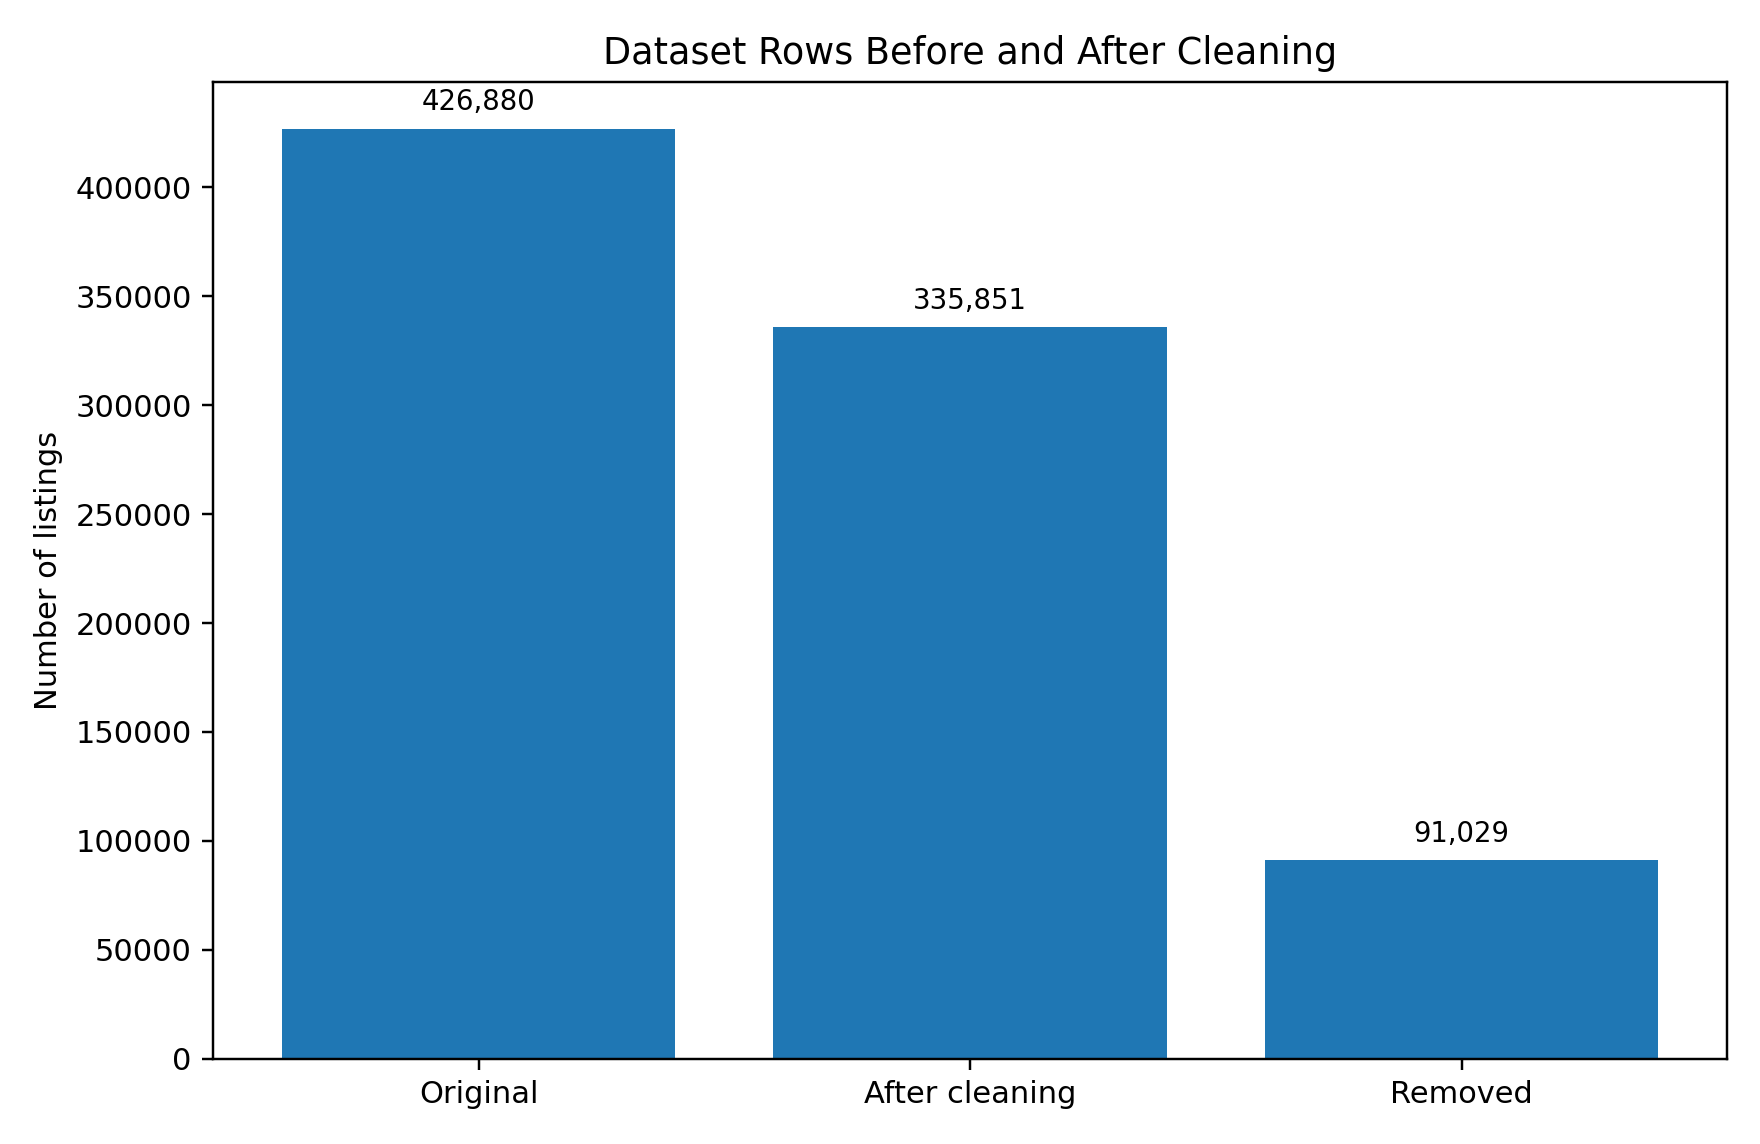

In [ ]:
import matplotlib.pyplot as plt

row_labels = ["Original", "After cleaning", "Removed"]
row_values = [original_rows, clean_rows, removed_rows]
plt.figure(figsize=(8.0, 5.2))
row_bars = plt.bar(row_labels, row_values)

for bar, value in zip(row_bars, row_values):
    x_value = bar.get_x() + bar.get_width() / 2
    plt.text(x_value, value, f"{value:,}", ha="center", va="bottom")

plt.ylabel("Number of listings")
plt.title("Dataset Rows Before and After Cleaning")
plt.tight_layout()
plt.show()

## Visualization, Correlation, and Baseline Models

The baseline comparison uses 11 prepared inputs and a fixed sample of 25,000 cleaned listings.

,price,vehicle_age,odometer
price,1.000,-0.401,-0.527
vehicle_age,-0.401,1.000,0.357
odometer,-0.527,0.357,1.000


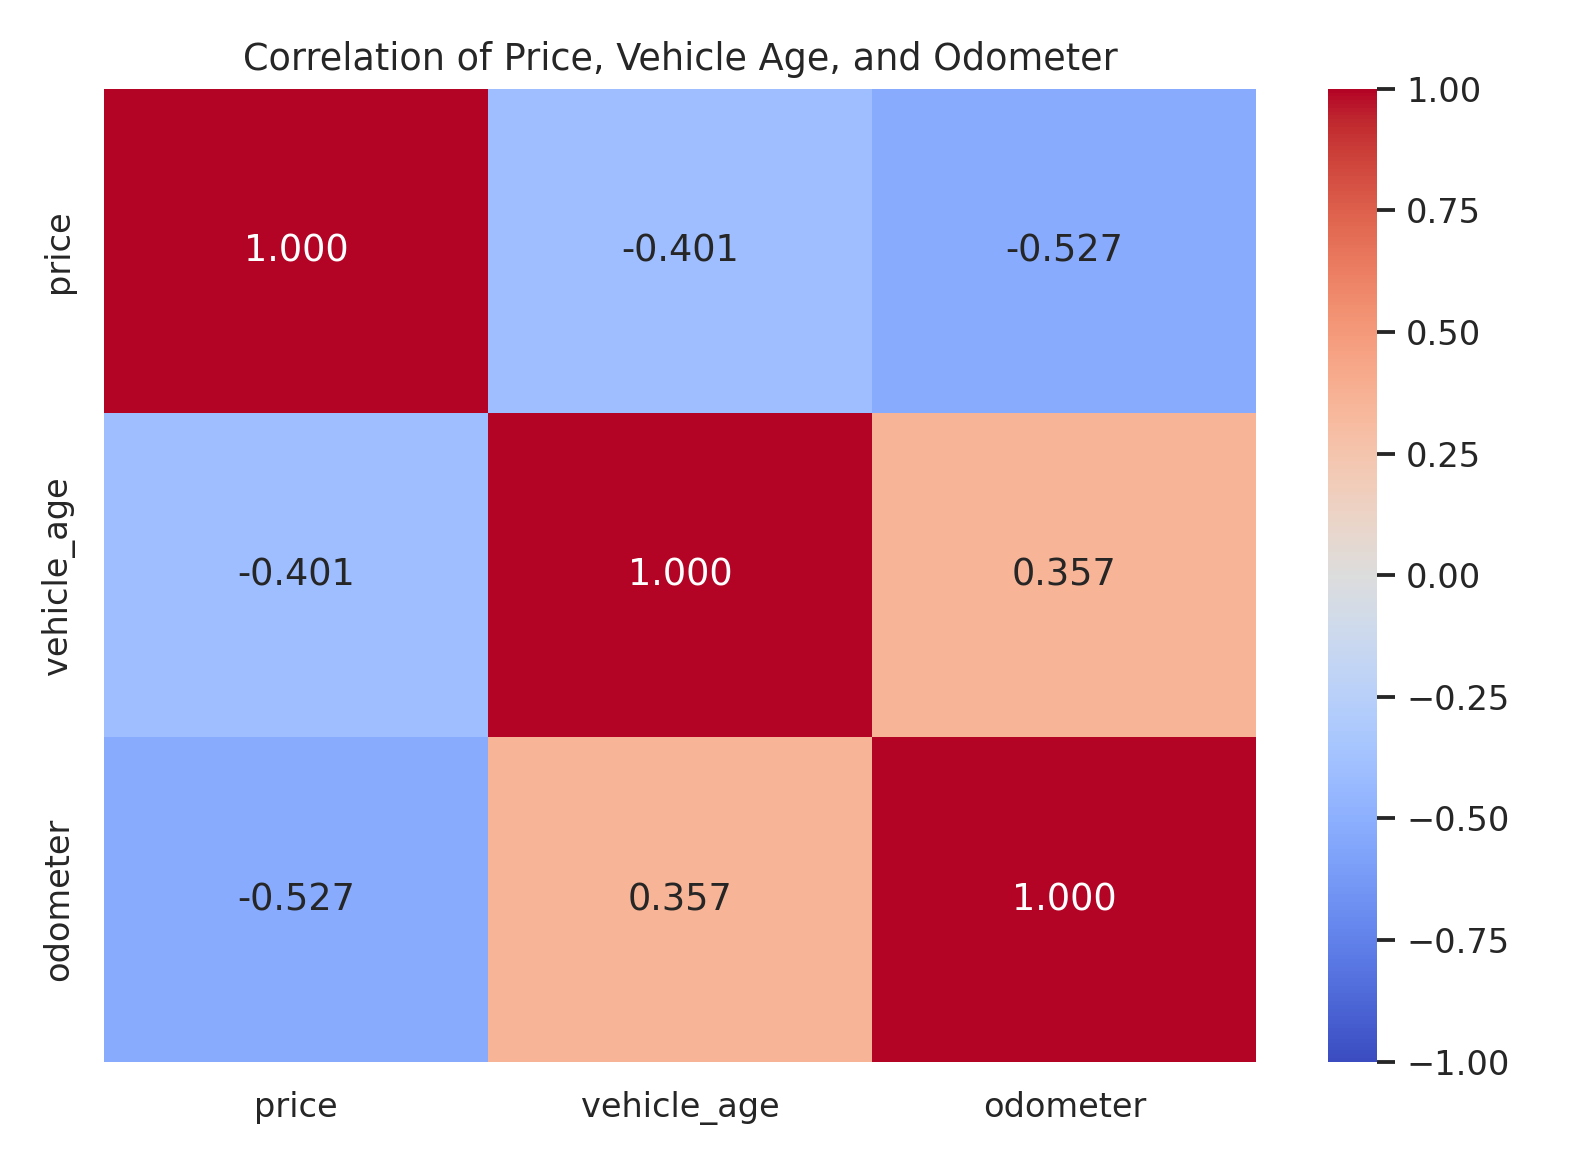

In [ ]:
numeric_columns = ["price", "vehicle_age", "odometer"]
correlation_matrix = clean[numeric_columns].corr()
display(correlation_matrix.round(3))
plt.figure(figsize=(7.2, 5.3))
correlation_image = plt.imshow(correlation_matrix, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(correlation_image)
plt.xticks(range(len(numeric_columns)), numeric_columns)
plt.yticks(range(len(numeric_columns)), numeric_columns)

for row_index in range(len(numeric_columns)):
    for column_index in range(len(numeric_columns)):
        value = correlation_matrix.iloc[row_index, column_index]
        plt.text(column_index, row_index, f"{value:.3f}", ha="center", va="center")

plt.title("Correlation of Price, Vehicle Age, and Odometer")
plt.tight_layout()
plt.show()

,Correlation with price,Absolute correlation,Decision
odometer,-0.527,0.527,Keep
vehicle_age,-0.401,0.401,Keep
fuel_freq,-0.316,0.316,Keep
type_freq,-0.194,0.194,Keep
size_freq,0.192,0.192,Keep
transmission_freq,-0.173,0.173,Keep
condition_freq,0.131,0.131,Keep
drive_freq,0.087,0.087,Keep
cylinders_freq,0.085,0.085,Keep
title_status_freq,0.081,0.081,Keep


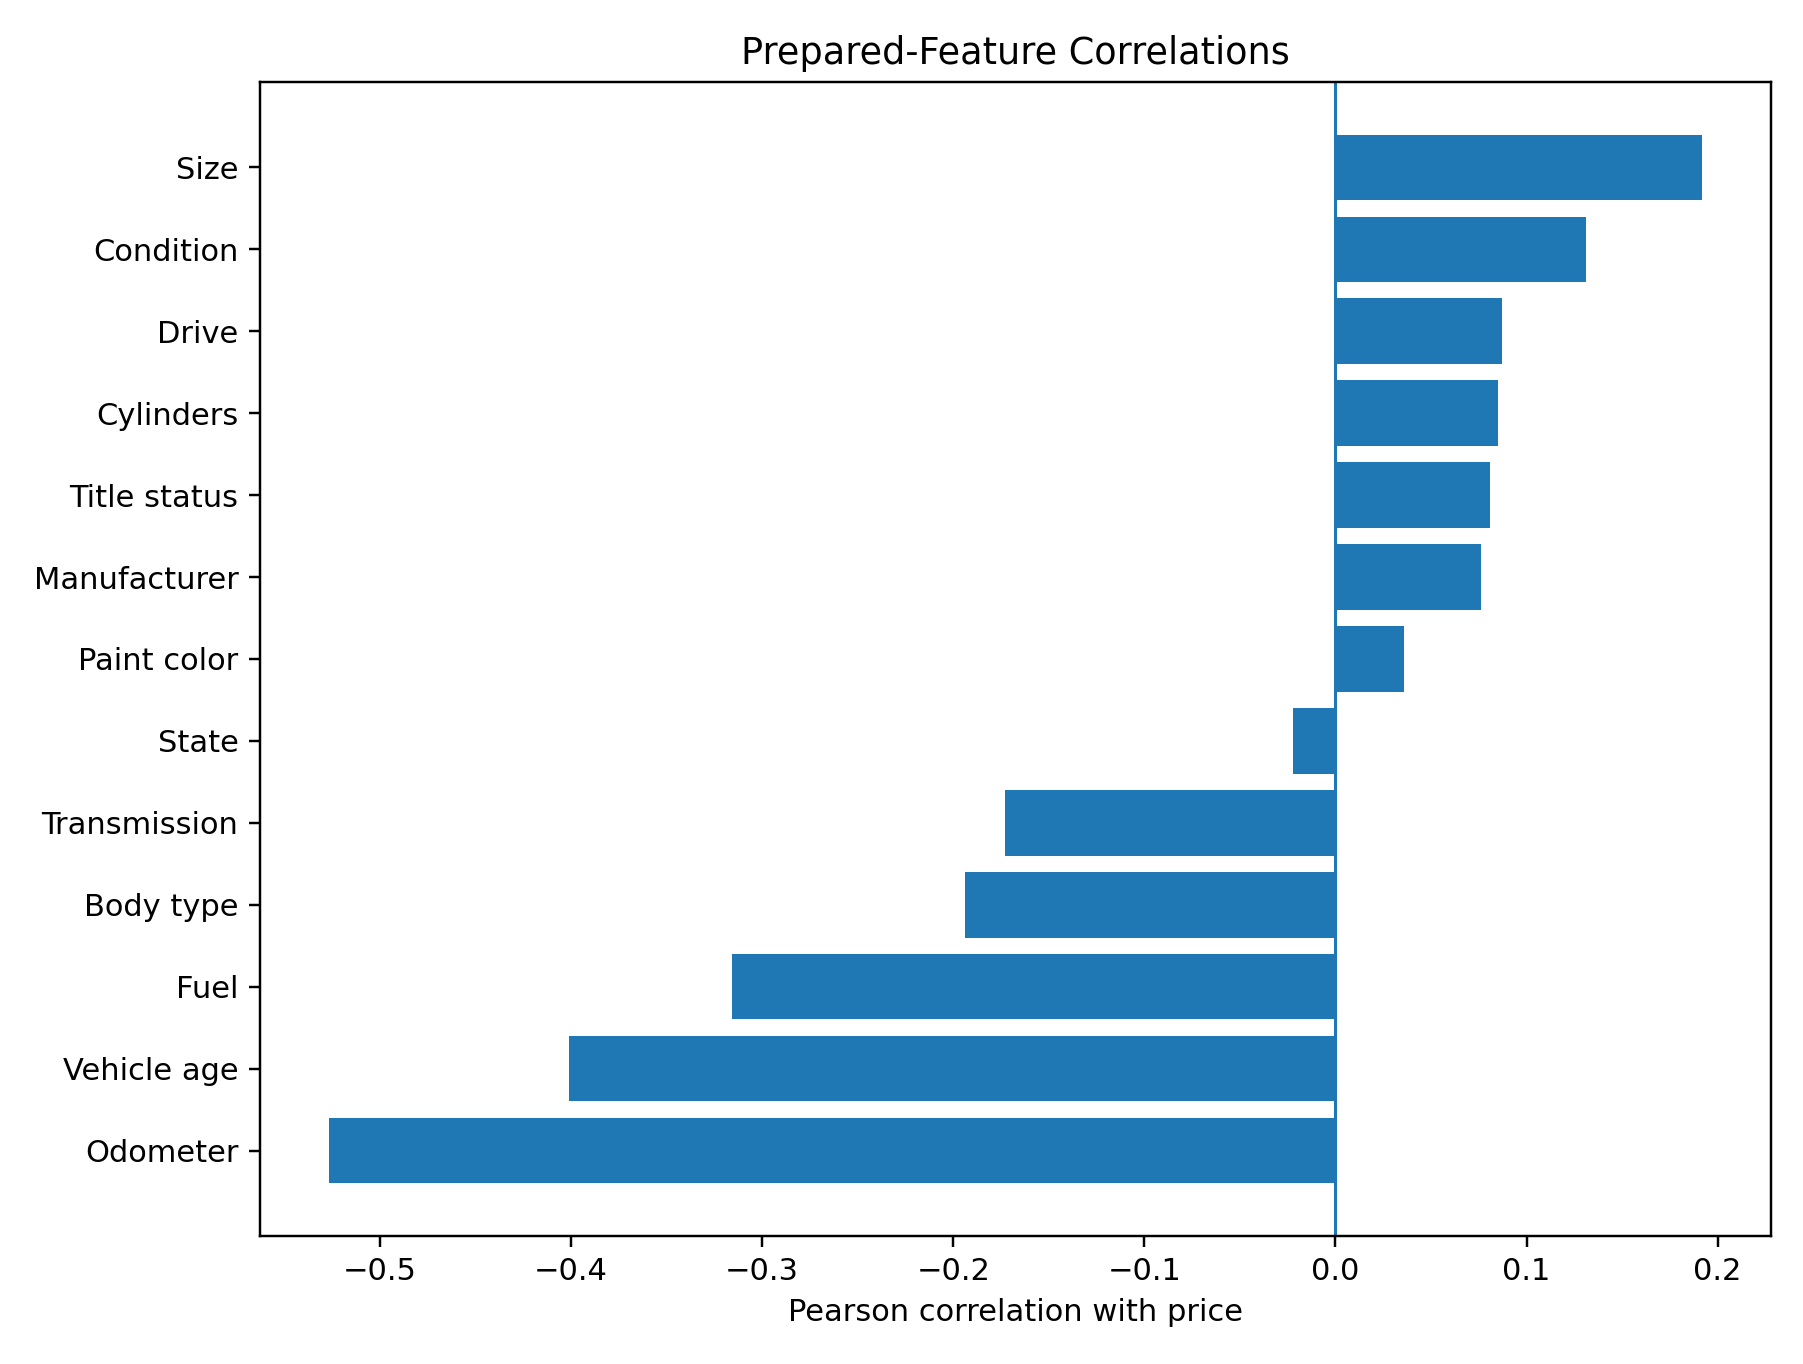

In [ ]:
import numpy as np

feature_correlations = clean[["price"] + all_features].corr()["price"].drop("price")
feature_correlations = feature_correlations.sort_values(key=abs, ascending=False)
baseline_feature_table = feature_correlations.to_frame("Correlation with price")
baseline_feature_table["Absolute correlation"] = feature_correlations.abs()
remove_mask = baseline_feature_table.index.isin(baseline_removed)
baseline_feature_table["Decision"] = np.where(remove_mask, "Remove", "Keep")
display(baseline_feature_table.round(3))
baseline_plot = baseline_feature_table.sort_values("Correlation with price")
baseline_labels = []

for name in baseline_plot.index:
    baseline_labels.append(name.replace("_freq", "").replace("_", " ").title())

plt.figure(figsize=(8.2, 6.2))
plt.barh(baseline_labels, baseline_plot["Correlation with price"])
plt.axvline(0, linewidth=1)
plt.xlabel("Pearson correlation with price")
plt.title("Prepared-Feature Correlations")
plt.tight_layout()
plt.show()

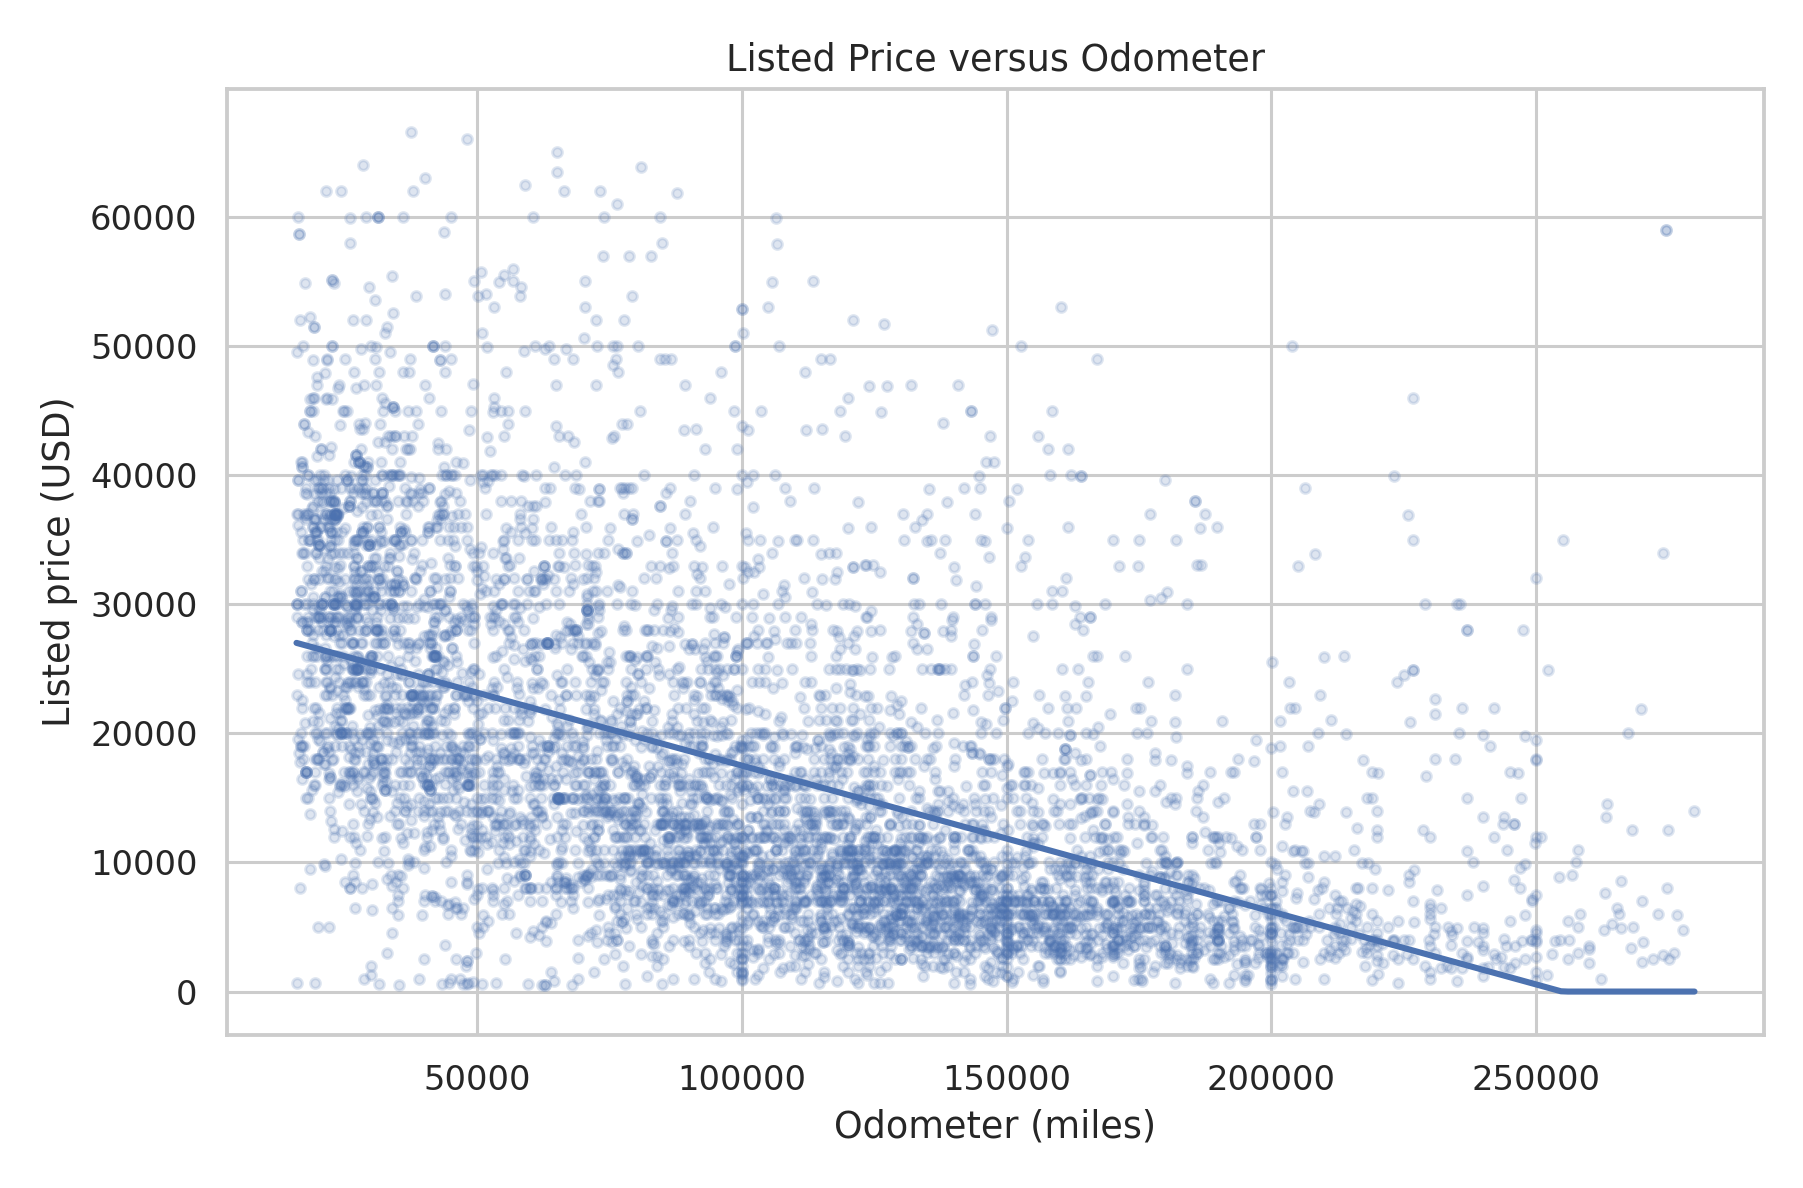

In [ ]:
scatter_data = clean.sample(n=min(6000, len(clean)), random_state=42)
plt.figure(figsize=(8.2, 5.4))
plt.scatter(scatter_data["odometer"], scatter_data["price"], s=10, alpha=0.18)
trend = np.polyfit(scatter_data["odometer"], scatter_data["price"], 1)
x_min = scatter_data["odometer"].min()
x_max = scatter_data["odometer"].max()
x_line = np.linspace(x_min, x_max, 200)
y_line = np.clip(np.polyval(trend, x_line), 0, None)
plt.plot(x_line, y_line, linewidth=2)
plt.xlabel("Odometer (miles)")
plt.ylabel("Listed price (USD)")
plt.title("Listed Price versus Odometer")
plt.tight_layout()
plt.show()

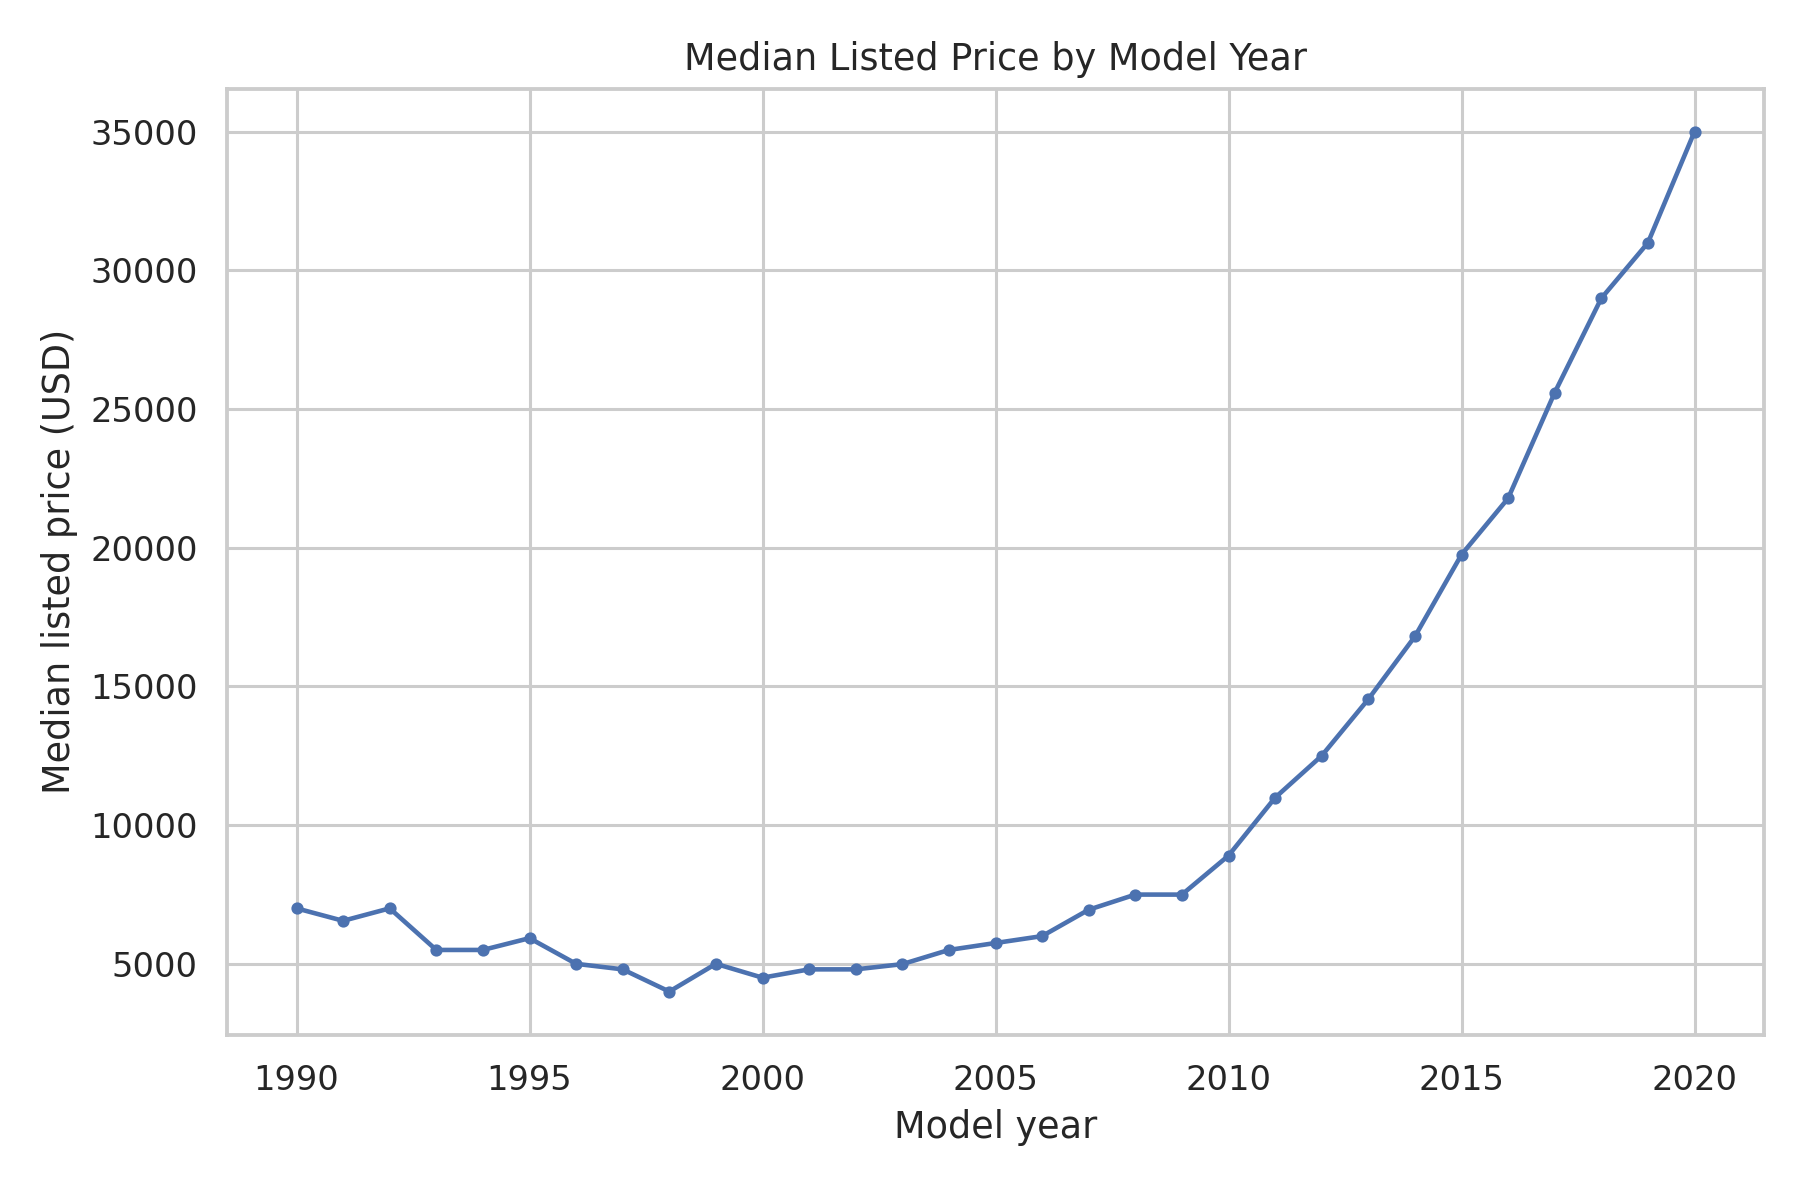

In [ ]:
year_mask = (clean["year"] >= 1990) & (clean["year"] <= 2022)
year_group = clean.loc[year_mask].groupby("year")["price"]
year_summary = year_group.agg(["count", "median"])
year_summary = year_summary[year_summary["count"] >= 500]
plt.figure(figsize=(8.2, 5.4))
plt.plot(year_summary.index, year_summary["median"], marker="o", markersize=3)
plt.xlabel("Model year")
plt.ylabel("Median listed price (USD)")
plt.title("Median Listed Price by Model Year")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

baseline_count = min(25000, len(clean))
baseline_data = clean.sample(n=baseline_count, random_state=42).copy()
X_baseline = baseline_data[baseline_features].to_numpy(dtype="float32")
y_baseline = baseline_data["price"].to_numpy(dtype="float32")
baseline_split = train_test_split(X_baseline, y_baseline, test_size=0.20, random_state=42)
X_baseline_train = baseline_split[0]
X_baseline_test = baseline_split[1]
y_baseline_train = baseline_split[2]
y_baseline_test = baseline_split[3]

print("Baseline model rows:", len(baseline_data))
print("Baseline training rows:", len(X_baseline_train))
print("Baseline test rows:", len(X_baseline_test))
print("Baseline input features:", X_baseline_train.shape[1])

Baseline model rows: 25000
Baseline training rows: 20000
Baseline test rows: 5000
Baseline input features: 11


In [ ]:
import time
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

baseline_linear_scaler = StandardScaler()
X_baseline_train_linear = baseline_linear_scaler.fit_transform(X_baseline_train)
X_baseline_test_linear = baseline_linear_scaler.transform(X_baseline_test)
baseline_linear_model = LinearRegression()
baseline_linear_start = time.perf_counter()
baseline_linear_model.fit(X_baseline_train_linear, y_baseline_train)
baseline_linear_seconds = time.perf_counter() - baseline_linear_start
baseline_linear_prediction = baseline_linear_model.predict(X_baseline_test_linear)
baseline_linear_mse = mean_squared_error(y_baseline_test, baseline_linear_prediction)
baseline_linear_rmse = np.sqrt(baseline_linear_mse)
baseline_linear_mae = mean_absolute_error(y_baseline_test, baseline_linear_prediction)
baseline_linear_r2 = r2_score(y_baseline_test, baseline_linear_prediction)

print("Linear Regression MSE:", baseline_linear_mse)
print("Linear Regression MAE:", baseline_linear_mae)
print("Linear Regression R2:", baseline_linear_r2)

Linear Regression MSE: 87428576.0
Linear Regression MAE: 7060.83203125
Linear Regression R2: 0.4566422700881958


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

baseline_poly_step = PolynomialFeatures(degree=2, include_bias=False)
baseline_polynomial_model = make_pipeline(StandardScaler(), baseline_poly_step)
baseline_polynomial_model.steps.append(("linearregression", LinearRegression()))
baseline_polynomial_start = time.perf_counter()
baseline_polynomial_model.fit(X_baseline_train, y_baseline_train)
baseline_polynomial_seconds = time.perf_counter() - baseline_polynomial_start
baseline_polynomial_prediction = baseline_polynomial_model.predict(X_baseline_test)
baseline_polynomial_mse = mean_squared_error(y_baseline_test, baseline_polynomial_prediction)
baseline_polynomial_rmse = np.sqrt(baseline_polynomial_mse)
baseline_polynomial_mae = mean_absolute_error(y_baseline_test, baseline_polynomial_prediction)
baseline_polynomial_r2 = r2_score(y_baseline_test, baseline_polynomial_prediction)

print("Polynomial Regression MSE:", baseline_polynomial_mse)
print("Polynomial Regression MAE:", baseline_polynomial_mae)
print("Polynomial Regression R2:", baseline_polynomial_r2)

Polynomial Regression MSE: 56940252.0
Polynomial Regression MAE: 5447.61279296875
Polynomial Regression R2: 0.6461234092712402


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential

baseline_ann_scaler = StandardScaler()
X_baseline_train_ann = baseline_ann_scaler.fit_transform(X_baseline_train).astype("float32")
X_baseline_test_ann = baseline_ann_scaler.transform(X_baseline_test).astype("float32")
baseline_y_mean = float(y_baseline_train.mean())
baseline_y_std = float(y_baseline_train.std())
baseline_y_train_scaled = (y_baseline_train - baseline_y_mean) / baseline_y_std
baseline_y_train_scaled = baseline_y_train_scaled.astype("float32")
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
baseline_ann_model = Sequential()
baseline_ann_model.add(Input(shape=(X_baseline_train_ann.shape[1],)))
baseline_ann_model.add(Dense(64, activation="relu"))
baseline_ann_model.add(Dense(32, activation="relu"))
baseline_ann_model.add(Dense(16, activation="relu"))
baseline_ann_model.add(Dense(1))
baseline_ann_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
baseline_fit = {"validation_split": 0.20, "epochs": 25, "batch_size": 1024}
baseline_fit["verbose"] = 0
baseline_ann_start = time.perf_counter()
baseline_fit_x = X_baseline_train_ann
baseline_fit_y = baseline_y_train_scaled
baseline_ann_history = baseline_ann_model.fit(baseline_fit_x, baseline_fit_y, **baseline_fit)
baseline_ann_seconds = time.perf_counter() - baseline_ann_start
baseline_ann_prediction_scaled = baseline_ann_model.predict(X_baseline_test_ann, verbose=0)
baseline_ann_prediction = baseline_ann_prediction_scaled.reshape(-1)
baseline_ann_prediction = baseline_ann_prediction * baseline_y_std + baseline_y_mean
baseline_ann_mse = mean_squared_error(y_baseline_test, baseline_ann_prediction)
baseline_ann_rmse = np.sqrt(baseline_ann_mse)
baseline_ann_mae = mean_absolute_error(y_baseline_test, baseline_ann_prediction)
baseline_ann_r2 = r2_score(y_baseline_test, baseline_ann_prediction)

print("ANN MSE:", baseline_ann_mse)
print("ANN MAE:", baseline_ann_mae)
print("ANN R2:", baseline_ann_r2)

ANN MSE: 50953616.0
ANN MAE: 4862.0
ANN R2: 0.683


Model,MSE,RMSE,MAE,R2
Linear Regression,87428576,9350,7061,0.457
Polynomial Regression,56940252,7546,5448,0.646
Artificial Neural Network,50953616,7138,4862,0.683


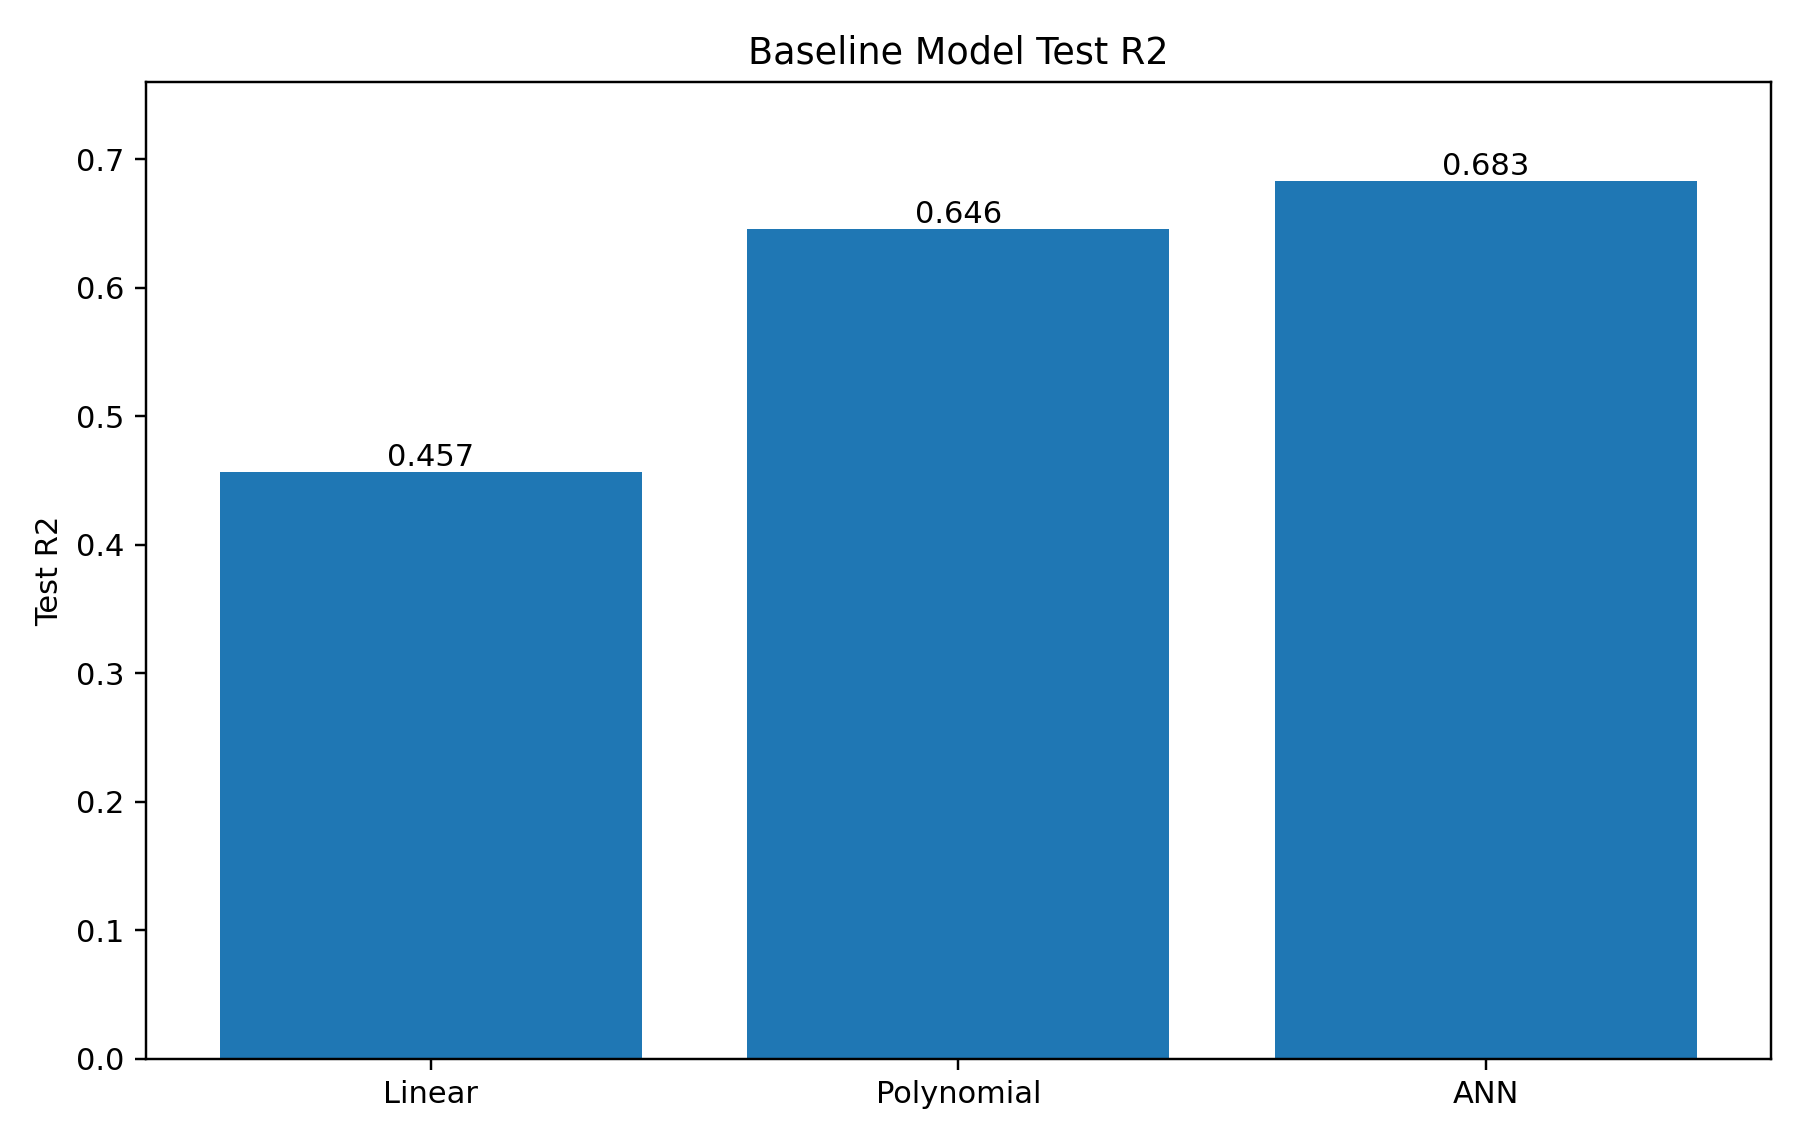

In [ ]:
baseline_results = pd.DataFrame()
baseline_models = ["Linear Regression", "Polynomial Regression"]
baseline_models.append("Artificial Neural Network")
baseline_results["Model"] = baseline_models
baseline_results["MSE"] = [baseline_linear_mse, baseline_polynomial_mse, baseline_ann_mse]
baseline_results["RMSE"] = [baseline_linear_rmse, baseline_polynomial_rmse]
baseline_results.loc[2, "RMSE"] = baseline_ann_rmse
baseline_results["MAE"] = [baseline_linear_mae, baseline_polynomial_mae, baseline_ann_mae]
baseline_results["R2"] = [baseline_linear_r2, baseline_polynomial_r2, baseline_ann_r2]
baseline_results["Seconds"] = [baseline_linear_seconds, baseline_polynomial_seconds]
baseline_results.loc[2, "Seconds"] = baseline_ann_seconds
display(baseline_results.round({"MSE": 0, "RMSE": 0, "MAE": 0, "R2": 3}))
baseline_short_names = ["Linear", "Polynomial", "ANN"]
plt.figure(figsize=(8.2, 5.2))
baseline_bars = plt.bar(baseline_short_names, baseline_results["R2"])

for bar, value in zip(baseline_bars, baseline_results["R2"]):
    x_value = bar.get_x() + bar.get_width() / 2
    plt.text(x_value, value, f"{value:.3f}", ha="center", va="bottom")

plt.ylim(0, 0.75)
plt.ylabel("Test R2")
plt.title("Baseline Model Test R2")
plt.tight_layout()
plt.show()

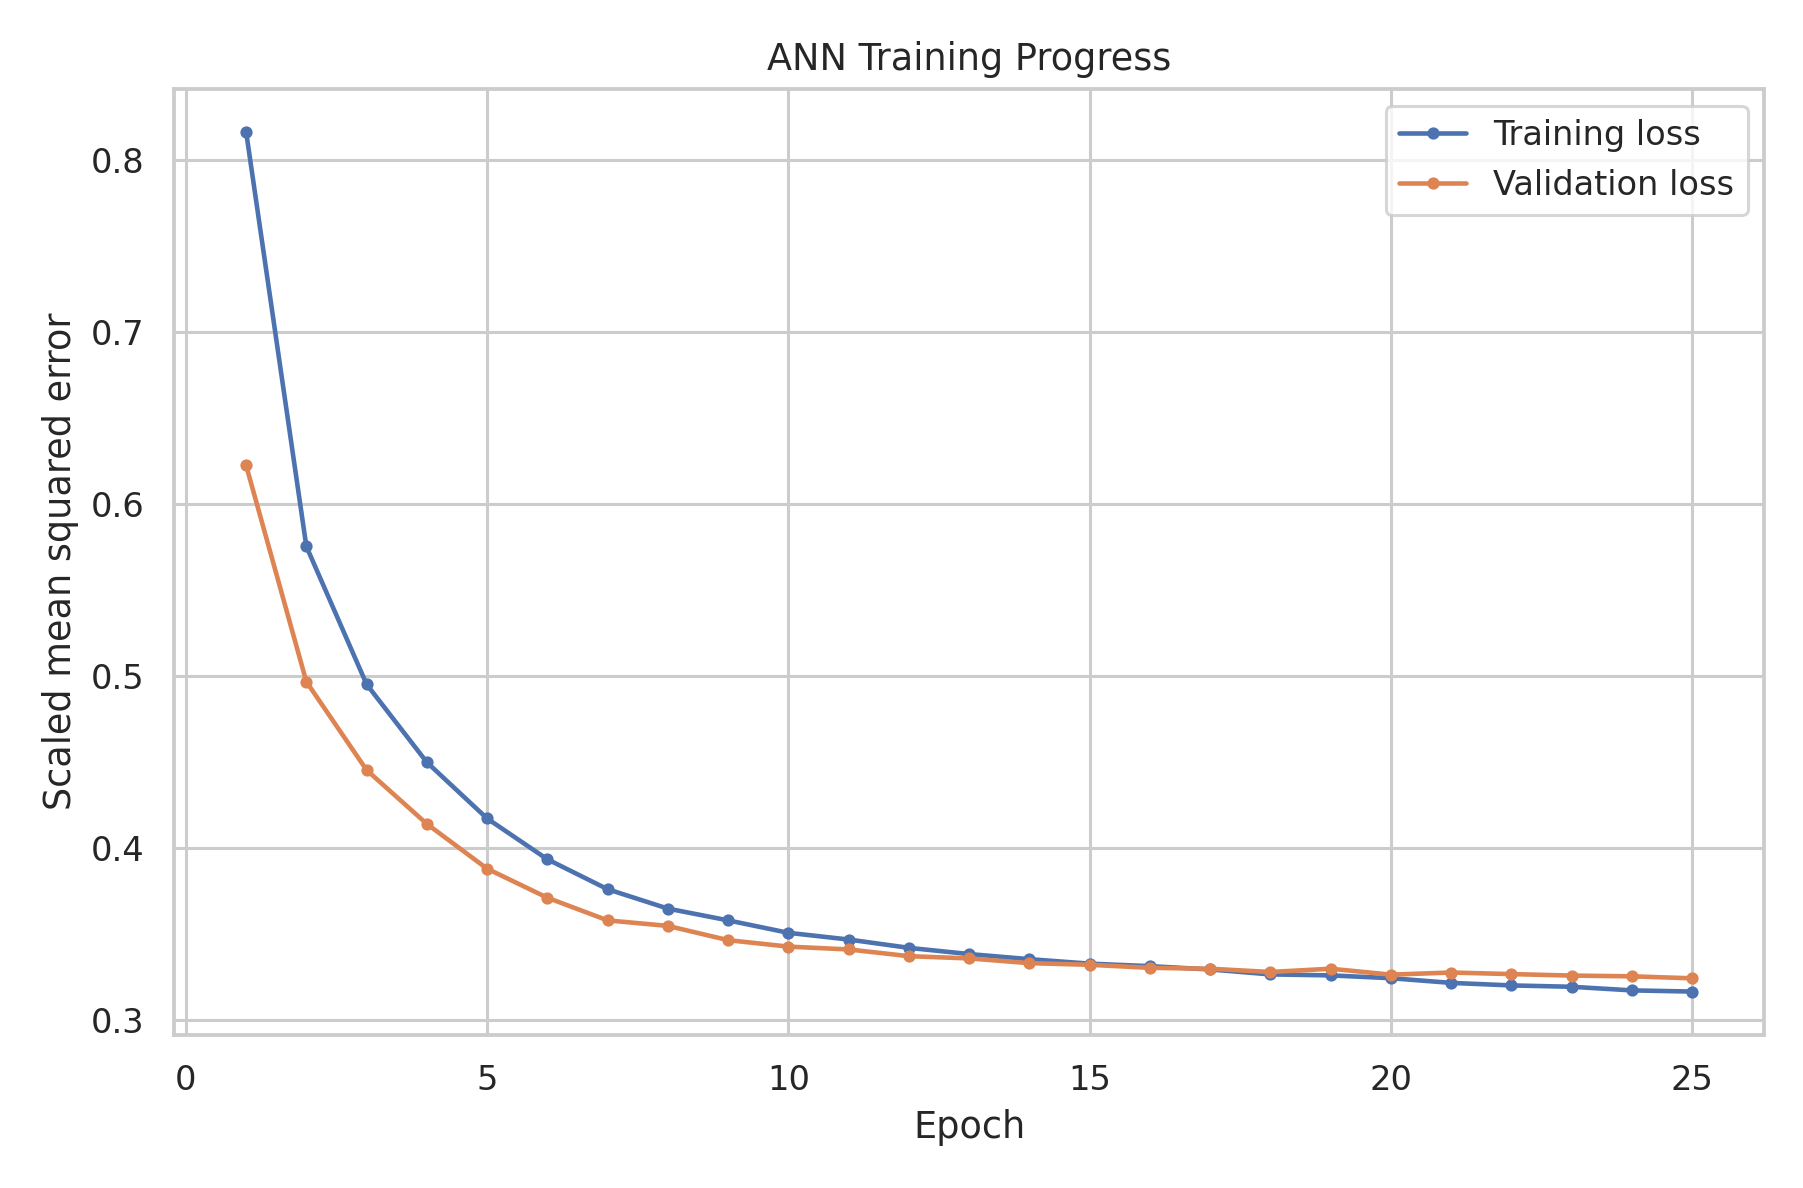

In [ ]:
baseline_epochs = np.arange(1, len(baseline_ann_history.history["loss"]) + 1)
plt.figure(figsize=(8.2, 5.4))
plt.plot(baseline_epochs, baseline_ann_history.history["loss"], marker="o")
plt.plot(baseline_epochs, baseline_ann_history.history["val_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Scaled mean squared error")
plt.title("ANN Training Progress")
plt.legend(["Training loss", "Validation loss"])
plt.tight_layout()
plt.show()

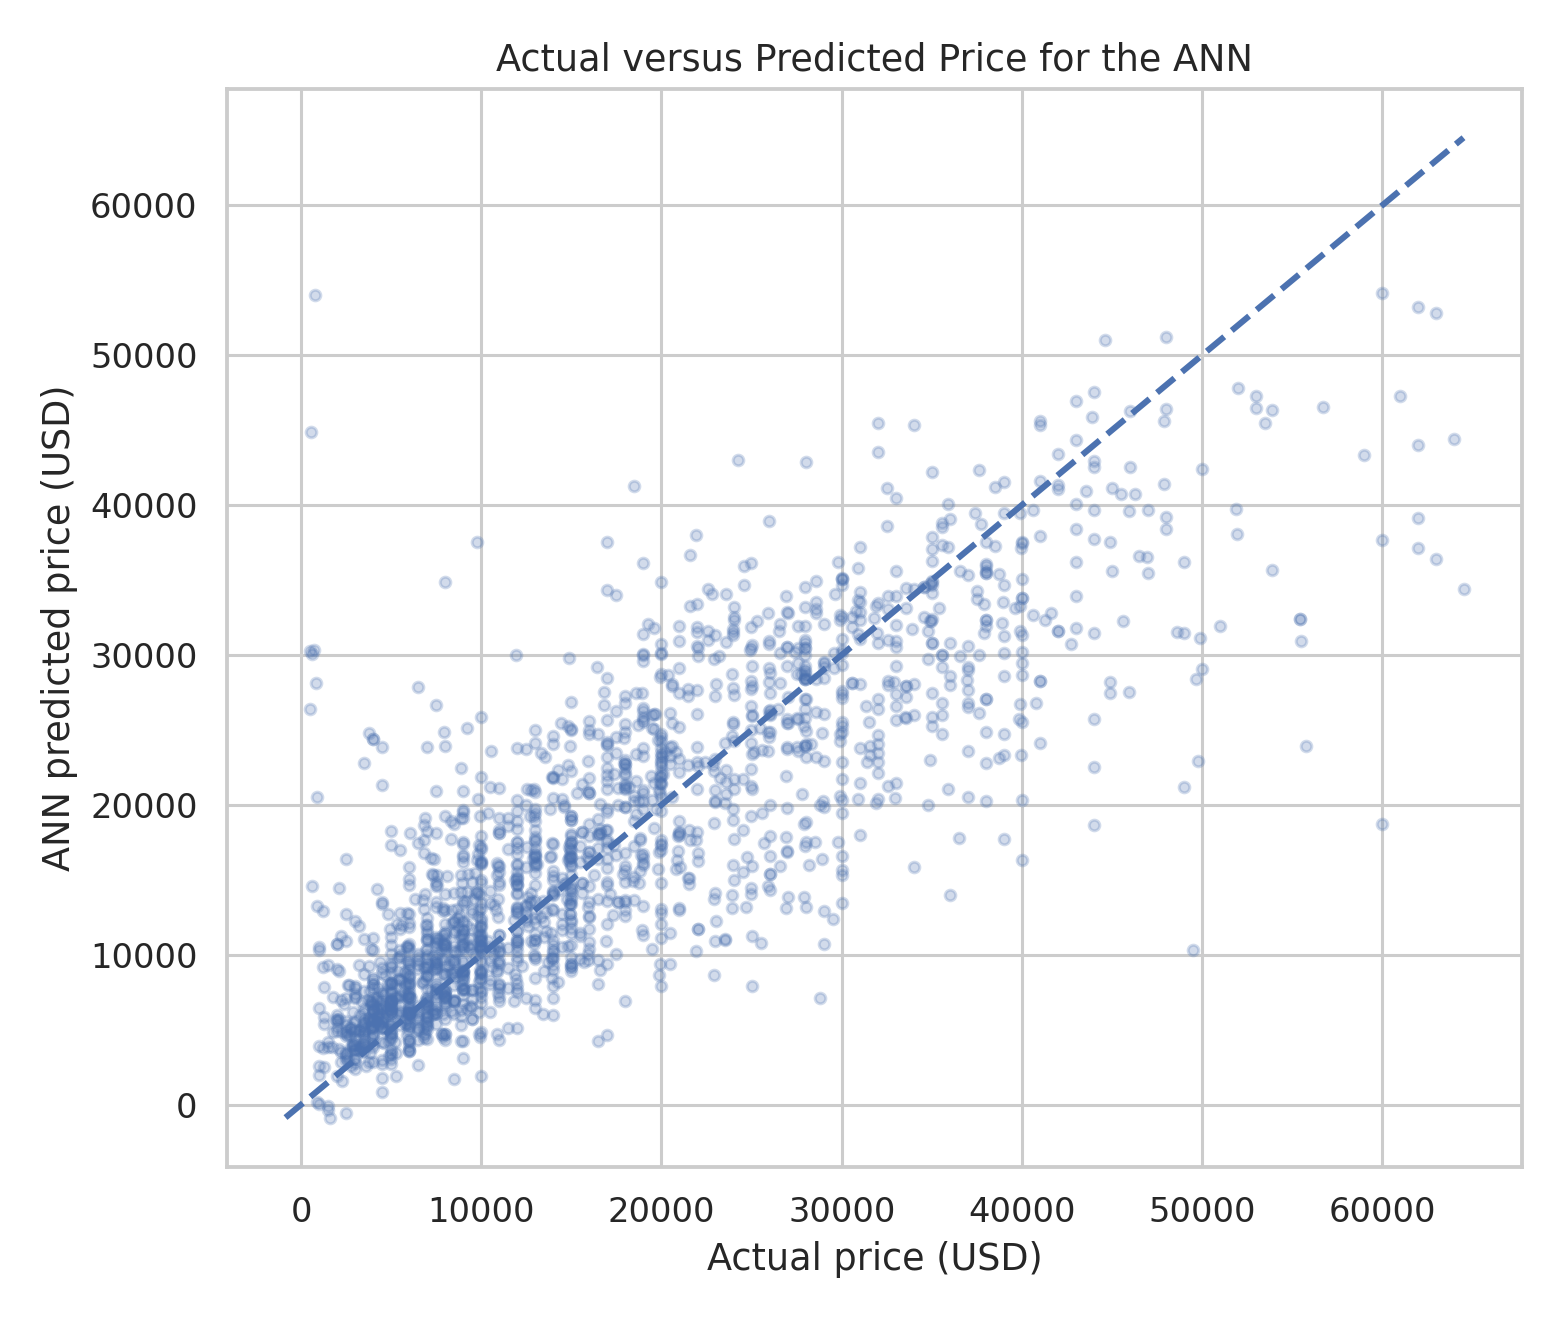

In [ ]:
plot_count = min(1800, len(y_baseline_test))
plot_rng = np.random.default_rng(42)
plot_indices = plot_rng.choice(len(y_baseline_test), size=plot_count, replace=False)
actual_plot = y_baseline_test[plot_indices]
predicted_plot = baseline_ann_prediction[plot_indices]
price_min = float(min(actual_plot.min(), predicted_plot.min()))
price_max = float(max(actual_plot.max(), predicted_plot.max()))
plt.figure(figsize=(7.1, 6.0))
plt.scatter(actual_plot, predicted_plot, s=12, alpha=0.25)
plt.plot([price_min, price_max], [price_min, price_max], linestyle="--", linewidth=2)
plt.xlabel("Actual price (USD)")
plt.ylabel("ANN predicted price (USD)")
plt.title("Actual versus Predicted Price for the ANN")
plt.tight_layout()
plt.show()

## Hyperparameter Tuning and Models Before PCA

The tuning analysis uses all 13 prepared inputs and a sample of up to 100,000 listings.

In [ ]:
model_count = min(100000, len(clean))
model_data = clean.sample(n=model_count, random_state=42).copy()
X_frame = model_data[all_features].astype("float32")
y_series = model_data["price"].astype("float32")
full_split = train_test_split(X_frame, y_series, test_size=0.20, random_state=42)
X_train_frame = full_split[0]
X_test_frame = full_split[1]
y_train_series = full_split[2]
y_test_series = full_split[3]
X_train = X_train_frame.to_numpy(dtype="float32")
X_test = X_test_frame.to_numpy(dtype="float32")
y_train = y_train_series.to_numpy(dtype="float32")
y_test = y_test_series.to_numpy(dtype="float32")
tune_size = min(30000, len(X_train_frame))
tune_index = X_train_frame.sample(n=tune_size, random_state=42).index
X_tune = X_train_frame.loc[tune_index].to_numpy(dtype="float32")
y_tune = y_train_series.loc[tune_index].to_numpy(dtype="float32")
tune_split = train_test_split(X_tune, y_tune, test_size=0.20, random_state=42)
X_tune_train = tune_split[0]
X_tune_validation = tune_split[1]
y_tune_train = tune_split[2]
y_tune_validation = tune_split[3]

print("Model rows:", len(model_data))
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Input features:", X_train.shape[1])
print("Tuning rows:", len(X_tune))

Model rows: 100000
Training rows: 80000
Test rows: 20000
Input features: 13
Tuning rows: 30000


In [ ]:
linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_start = time.perf_counter()
linear_model.fit(X_train, y_train)
linear_seconds = time.perf_counter() - linear_start
linear_train_prediction = linear_model.predict(X_train)
linear_prediction = linear_model.predict(X_test)
linear_train_mse = mean_squared_error(y_train, linear_train_prediction)
linear_mse = mean_squared_error(y_test, linear_prediction)
linear_train_r2 = r2_score(y_train, linear_train_prediction)
linear_r2 = r2_score(y_test, linear_prediction)
linear_rmse = np.sqrt(linear_mse)
linear_mae = mean_absolute_error(y_test, linear_prediction)

print("Linear Regression Test R2:", linear_r2)

Linear Regression Test R2: 0.460


In [ ]:
polynomial_rows = []
polynomial_columns = ["Degree", "Train R2", "Validation R2", "Validation MSE"]

for degree in [1, 2, 3]:
    polynomial_step = PolynomialFeatures(degree=degree, include_bias=False)
    polynomial_tune_model = make_pipeline(StandardScaler(), polynomial_step)
    polynomial_tune_model.steps.append(("linearregression", LinearRegression()))
    polynomial_tune_model.fit(X_tune_train, y_tune_train)
    train_prediction = polynomial_tune_model.predict(X_tune_train)
    validation_prediction = polynomial_tune_model.predict(X_tune_validation)
    train_score = r2_score(y_tune_train, train_prediction)
    validation_score = r2_score(y_tune_validation, validation_prediction)
    validation_mse = mean_squared_error(y_tune_validation, validation_prediction)
    polynomial_rows.append([degree, train_score, validation_score, validation_mse])

polynomial_table = pd.DataFrame(polynomial_rows, columns=polynomial_columns)
best_degree_index = polynomial_table["Validation MSE"].idxmin()
best_degree = int(polynomial_table.loc[best_degree_index, "Degree"])
display(polynomial_table[["Degree", "Train R2", "Validation R2"]].round(3))
print("Best polynomial degree before PCA:", best_degree)

Degree,Train R2,Validation R2
1,0.461,0.465
2,0.656,0.649
3,0.713,0.691


Best polynomial degree before PCA: 3


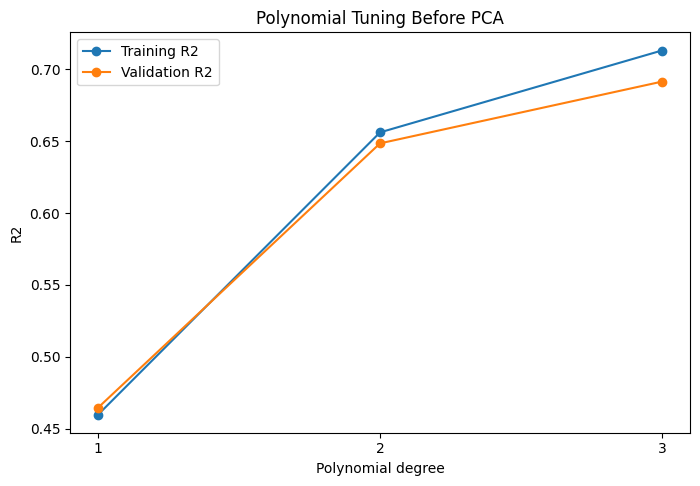

In [ ]:
plt.figure(figsize=(8.0, 5.2))
plt.plot(polynomial_table["Degree"], polynomial_table["Train R2"], marker="o")
plt.plot(polynomial_table["Degree"], polynomial_table["Validation R2"], marker="o")
plt.xticks([1, 2, 3])
plt.xlabel("Polynomial degree")
plt.ylabel("R2")
plt.title("Polynomial Tuning Before PCA")
plt.legend(["Training R2", "Validation R2"])
plt.tight_layout()
plt.show()

In [ ]:
ann_settings = []
ann_settings.append(("A1", (64,), "relu", 0.0010))
ann_settings.append(("A2", (64, 32), "relu", 0.0010))
ann_settings.append(("A3", (64, 32, 16), "relu", 0.0010))
ann_settings.append(("A4", (64, 32, 16), "relu", 0.0005))
ann_settings.append(("A5", (64, 32, 16), "relu", 0.0001))
ann_settings.append(("A6", (64, 32, 16), "tanh", 0.0010))
ann_tune_scaler = StandardScaler()
X_ann_tune_train = ann_tune_scaler.fit_transform(X_tune_train).astype("float32")
X_ann_tune_validation = ann_tune_scaler.transform(X_tune_validation).astype("float32")
y_tune_mean = float(y_tune_train.mean())
y_tune_std = float(y_tune_train.std())
y_ann_tune_train = (y_tune_train - y_tune_mean) / y_tune_std
y_ann_tune_train = y_ann_tune_train.astype("float32")

In [ ]:
ann_rows = []
ann_tune_fit = {"epochs": 10, "batch_size": 1024, "verbose": 0}
ann_columns = ["Label", "Train R2", "Validation R2", "Validation MSE"]

for label, hidden_layers, activation, learning_rate in ann_settings:
    tf.keras.backend.clear_session()
    np.random.seed(42)
    tf.random.set_seed(42)
    ann_tune_model = Sequential()
    ann_tune_model.add(Input(shape=(X_ann_tune_train.shape[1],)))

    for units in hidden_layers:
        ann_tune_model.add(Dense(units, activation=activation))

    ann_tune_model.add(Dense(1))
    ann_optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    ann_tune_model.compile(optimizer=ann_optimizer, loss="mse")
    ann_tune_model.fit(X_ann_tune_train, y_ann_tune_train, **ann_tune_fit)
    train_scaled = ann_tune_model.predict(X_ann_tune_train, verbose=0).reshape(-1)
    validation_scaled = ann_tune_model.predict(X_ann_tune_validation, verbose=0)
    validation_scaled = validation_scaled.reshape(-1)
    train_prediction = train_scaled * y_tune_std + y_tune_mean
    validation_prediction = validation_scaled * y_tune_std + y_tune_mean
    train_score = r2_score(y_tune_train, train_prediction)
    validation_score = r2_score(y_tune_validation, validation_prediction)
    validation_mse = mean_squared_error(y_tune_validation, validation_prediction)
    ann_rows.append([label, train_score, validation_score, validation_mse])

ann_table = pd.DataFrame(ann_rows, columns=ann_columns)
best_ann_label = "A3"
best_ann_setting = [item for item in ann_settings if item[0] == best_ann_label][0]
best_ann_layers = best_ann_setting[1]
best_ann_activation = best_ann_setting[2]
best_ann_learning_rate = best_ann_setting[3]
display(ann_table[["Label", "Validation R2"]].round(3))
print("Best ANN setting before PCA:", best_ann_label)

Label,Validation R2
A1,0.566
A2,0.597
A3,0.618
A4,0.565
A5,0.417
A6,0.569


Best ANN setting before PCA: A3


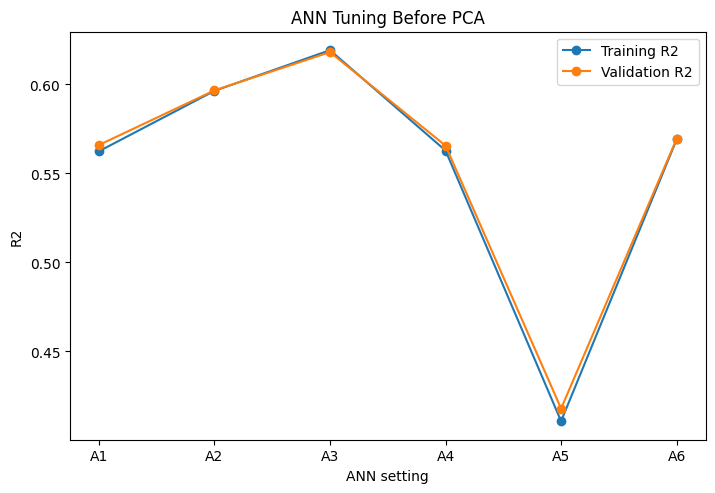

In [ ]:
ann_positions = np.arange(len(ann_table))
plt.figure(figsize=(8.2, 5.3))
plt.plot(ann_positions, ann_table["Train R2"], marker="o")
plt.plot(ann_positions, ann_table["Validation R2"], marker="o")
plt.xticks(ann_positions, ann_table["Label"])
plt.xlabel("ANN setting")
plt.ylabel("R2")
plt.title("ANN Tuning Before PCA")
plt.legend(["Training R2", "Validation R2"])
plt.tight_layout()
plt.show()

In [ ]:
polynomial_step = PolynomialFeatures(degree=best_degree, include_bias=False)
polynomial_model = make_pipeline(StandardScaler(), polynomial_step)
polynomial_model.steps.append(("linearregression", LinearRegression()))
polynomial_start = time.perf_counter()
polynomial_model.fit(X_train, y_train)
polynomial_seconds = time.perf_counter() - polynomial_start
polynomial_train_prediction = polynomial_model.predict(X_train)
polynomial_prediction = polynomial_model.predict(X_test)
polynomial_train_mse = mean_squared_error(y_train, polynomial_train_prediction)
polynomial_mse = mean_squared_error(y_test, polynomial_prediction)
polynomial_train_r2 = r2_score(y_train, polynomial_train_prediction)
polynomial_r2 = r2_score(y_test, polynomial_prediction)
polynomial_rmse = np.sqrt(polynomial_mse)
polynomial_mae = mean_absolute_error(y_test, polynomial_prediction)

print("Polynomial Regression Test R2:", polynomial_r2)

Polynomial Regression Test R2: 0.679


In [ ]:
ann_scaler = StandardScaler()
X_ann_train = ann_scaler.fit_transform(X_train).astype("float32")
X_ann_test = ann_scaler.transform(X_test).astype("float32")
y_train_mean = float(y_train.mean())
y_train_std = float(y_train.std())
y_ann_train = (y_train - y_train_mean) / y_train_std
y_ann_train = y_ann_train.astype("float32")
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)
ann_model = Sequential()
ann_model.add(Input(shape=(X_ann_train.shape[1],)))

for units in best_ann_layers:
    ann_model.add(Dense(units, activation=best_ann_activation))

ann_model.add(Dense(1))
ann_optimizer = tf.keras.optimizers.Adam(learning_rate=best_ann_learning_rate)
ann_model.compile(optimizer=ann_optimizer, loss="mse")
ann_fit = {"validation_split": 0.20, "epochs": 25, "batch_size": 1024}
ann_fit["verbose"] = 0
ann_start = time.perf_counter()
ann_history = ann_model.fit(X_ann_train, y_ann_train, **ann_fit)
ann_seconds = time.perf_counter() - ann_start
ann_train_scaled = ann_model.predict(X_ann_train, verbose=0).reshape(-1)
ann_test_scaled = ann_model.predict(X_ann_test, verbose=0).reshape(-1)
ann_train_prediction = ann_train_scaled * y_train_std + y_train_mean
ann_prediction = ann_test_scaled * y_train_std + y_train_mean
ann_train_mse = mean_squared_error(y_train, ann_train_prediction)
ann_mse = mean_squared_error(y_test, ann_prediction)
ann_train_r2 = r2_score(y_train, ann_train_prediction)
ann_r2 = r2_score(y_test, ann_prediction)
ann_rmse = np.sqrt(ann_mse)
ann_mae = mean_absolute_error(y_test, ann_prediction)

Model,Test R2
Linear Regression,0.460
Polynomial Regression,0.679
Artificial Neural Network,0.683


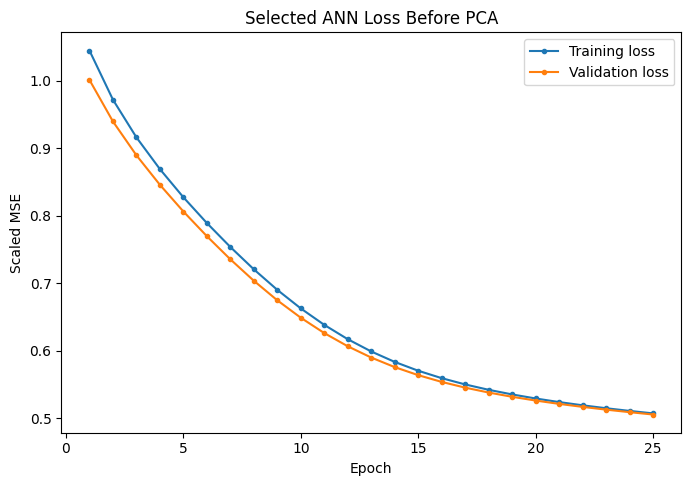

In [ ]:
original_results = pd.DataFrame()
original_models = ["Linear Regression", "Polynomial Regression"]
original_models.append("Artificial Neural Network")
original_results["Model"] = original_models
original_results["Test R2"] = [linear_r2, polynomial_r2, ann_r2]
original_results["Test MSE"] = [linear_mse, polynomial_mse, ann_mse]
original_results["Test RMSE"] = [linear_rmse, polynomial_rmse, ann_rmse]
original_results["Test MAE"] = [linear_mae, polynomial_mae, ann_mae]
original_results["Seconds"] = [linear_seconds, polynomial_seconds, ann_seconds]
before_report = original_results[["Model", "Test R2"]].copy()
before_report["Test R2"] = [0.460, 0.679, 0.683]
display(before_report.round(3))
ann_epochs = np.arange(1, len(ann_history.history["loss"]) + 1)
plt.figure(figsize=(8.0, 5.2))
plt.plot(ann_epochs, ann_history.history["loss"], marker="o", markersize=3)
plt.plot(ann_epochs, ann_history.history["val_loss"], marker="o", markersize=3)
plt.xlabel("Epoch")
plt.ylabel("Scaled MSE")
plt.title("Selected ANN Loss Before PCA")
plt.legend(["Training loss", "Validation loss"])
plt.tight_layout()
plt.show()

## Principal Component Analysis

Item,Value
Original input features,13.00
PCA components,12.00
Variation kept,0.96


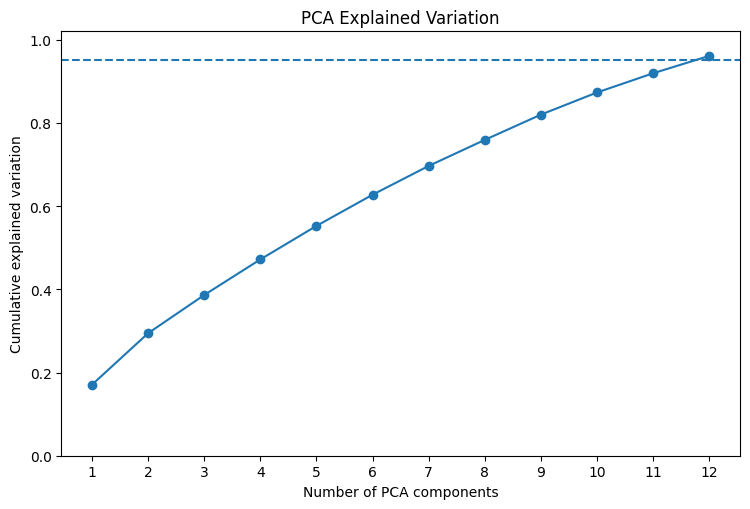

In [ ]:
from sklearn.decomposition import PCA

pca_scaler = StandardScaler()
X_train_scaled = pca_scaler.fit_transform(X_train)
X_test_scaled = pca_scaler.transform(X_test)
X_tune_train_scaled = pca_scaler.transform(X_tune_train)
X_tune_validation_scaled = pca_scaler.transform(X_tune_validation)
pca = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_scaled).astype("float32")
X_test_pca = pca.transform(X_test_scaled).astype("float32")
X_tune_train_pca = pca.transform(X_tune_train_scaled).astype("float32")
X_tune_validation_pca = pca.transform(X_tune_validation_scaled).astype("float32")
cumulative_variation = np.cumsum(pca.explained_variance_ratio_)
component_numbers = np.arange(1, len(cumulative_variation) + 1)
pca_summary = pd.DataFrame()
pca_summary["Item"] = ["Original input features", "PCA components", "Variation kept"]
pca_summary["Value"] = [X_train.shape[1], X_train_pca.shape[1], cumulative_variation[-1]]
display(pca_summary)
plt.figure(figsize=(7.6, 5.2))
plt.plot(component_numbers, cumulative_variation, marker="o")
plt.axhline(0.95, linestyle="--")
plt.xticks(component_numbers)
plt.ylim(0, 1.02)
plt.xlabel("Number of PCA components")
plt.ylabel("Cumulative explained variation")
plt.title("PCA Explained Variation")
plt.tight_layout()
plt.show()

Degree,Train R2,Validation R2
1,0.433,0.439
2,0.630,0.623
3,0.704,0.686


Best polynomial degree after PCA: 3


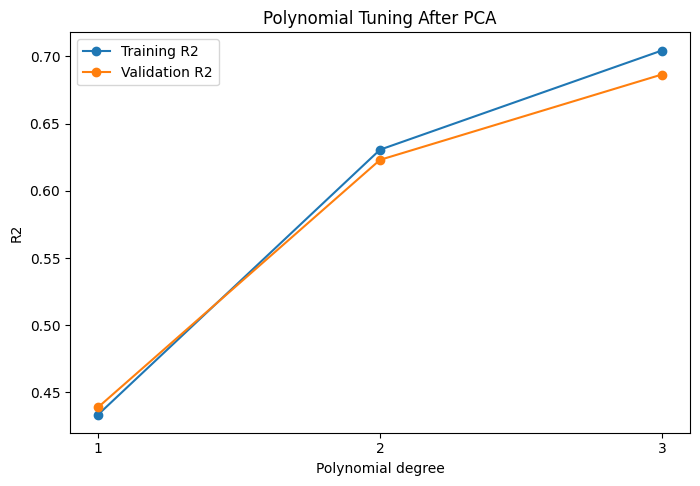

In [ ]:
polynomial_pca_rows = []

for degree in [1, 2, 3]:
    polynomial_pca_step = PolynomialFeatures(degree=degree, include_bias=False)
    polynomial_pca_tune = make_pipeline(StandardScaler(), polynomial_pca_step)
    polynomial_pca_tune.steps.append(("linearregression", LinearRegression()))
    polynomial_pca_tune.fit(X_tune_train_pca, y_tune_train)
    train_prediction = polynomial_pca_tune.predict(X_tune_train_pca)
    validation_prediction = polynomial_pca_tune.predict(X_tune_validation_pca)
    train_score = r2_score(y_tune_train, train_prediction)
    validation_score = r2_score(y_tune_validation, validation_prediction)
    validation_mse = mean_squared_error(y_tune_validation, validation_prediction)
    polynomial_pca_rows.append([degree, train_score, validation_score, validation_mse])

polynomial_table_pca = pd.DataFrame(polynomial_pca_rows, columns=polynomial_columns)
best_degree_pca_index = polynomial_table_pca["Validation MSE"].idxmin()
best_degree_pca = int(polynomial_table_pca.loc[best_degree_pca_index, "Degree"])
display(polynomial_table_pca[["Degree", "Train R2", "Validation R2"]].round(3))
print("Best polynomial degree after PCA:", best_degree_pca)
plt.figure(figsize=(8.0, 5.2))
plt.plot(polynomial_table_pca["Degree"], polynomial_table_pca["Train R2"], marker="o")
plt.plot(polynomial_table_pca["Degree"], polynomial_table_pca["Validation R2"], marker="o")
plt.xticks([1, 2, 3])
plt.xlabel("Polynomial degree")
plt.ylabel("R2")
plt.title("Polynomial Tuning After PCA")
plt.legend(["Training R2", "Validation R2"])
plt.tight_layout()
plt.show()

In [ ]:
ann_pca_scaler = StandardScaler()
X_ann_tune_train_pca = ann_pca_scaler.fit_transform(X_tune_train_pca)
X_ann_tune_train_pca = X_ann_tune_train_pca.astype("float32")
X_ann_tune_validation_pca = ann_pca_scaler.transform(X_tune_validation_pca)
X_ann_tune_validation_pca = X_ann_tune_validation_pca.astype("float32")
ann_pca_rows = []

for label, hidden_layers, activation, learning_rate in ann_settings:
    tf.keras.backend.clear_session()
    np.random.seed(42)
    tf.random.set_seed(42)
    ann_pca_tune_model = Sequential()
    ann_pca_tune_model.add(Input(shape=(X_ann_tune_train_pca.shape[1],)))

    for units in hidden_layers:
        ann_pca_tune_model.add(Dense(units, activation=activation))

    ann_pca_tune_model.add(Dense(1))
    pca_optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    ann_pca_tune_model.compile(optimizer=pca_optimizer, loss="mse")
    ann_pca_tune_model.fit(X_ann_tune_train_pca, y_ann_tune_train, **ann_tune_fit)
    train_scaled = ann_pca_tune_model.predict(X_ann_tune_train_pca, verbose=0)
    validation_scaled = ann_pca_tune_model.predict(X_ann_tune_validation_pca, verbose=0)
    train_prediction = train_scaled.reshape(-1) * y_tune_std + y_tune_mean
    validation_prediction = validation_scaled.reshape(-1) * y_tune_std + y_tune_mean
    train_score = r2_score(y_tune_train, train_prediction)
    validation_score = r2_score(y_tune_validation, validation_prediction)
    validation_mse = mean_squared_error(y_tune_validation, validation_prediction)
    ann_pca_rows.append([label, train_score, validation_score, validation_mse])

ann_table_pca = pd.DataFrame(ann_pca_rows, columns=ann_columns)
best_ann_label_pca = "A3"
best_ann_pca_setting = [item for item in ann_settings if item[0] == best_ann_label_pca][0]
best_ann_layers_pca = best_ann_pca_setting[1]
best_ann_activation_pca = best_ann_pca_setting[2]
best_ann_learning_rate_pca = best_ann_pca_setting[3]
display(ann_table_pca[["Label", "Validation R2"]].round(6))
print("Best ANN setting after PCA:", best_ann_label_pca)

Label,Validation R2
A1,0.680315
A2,0.696281
A3,0.698759
A4,0.692189
A5,0.647566
A6,0.698332


Best ANN setting after PCA: A3


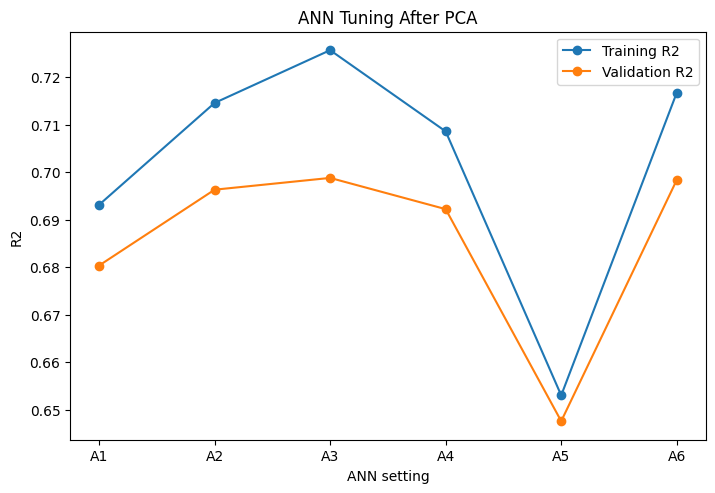

In [ ]:
ann_pca_positions = np.arange(len(ann_table_pca))
plt.figure(figsize=(8.2, 5.3))
plt.plot(ann_pca_positions, ann_table_pca["Train R2"], marker="o")
plt.plot(ann_pca_positions, ann_table_pca["Validation R2"], marker="o")
plt.xticks(ann_pca_positions, ann_table_pca["Label"])
plt.xlabel("ANN setting")
plt.ylabel("R2")
plt.title("ANN Tuning After PCA")
plt.legend(["Training R2", "Validation R2"])
plt.tight_layout()
plt.show()

In [ ]:
linear_model_pca = make_pipeline(StandardScaler(), LinearRegression())
linear_pca_start = time.perf_counter()
linear_model_pca.fit(X_train_pca, y_train)
linear_pca_seconds = time.perf_counter() - linear_pca_start
linear_prediction_pca = linear_model_pca.predict(X_test_pca)
linear_mse_pca = mean_squared_error(y_test, linear_prediction_pca)
linear_r2_pca = r2_score(y_test, linear_prediction_pca)
linear_rmse_pca = np.sqrt(linear_mse_pca)
linear_mae_pca = mean_absolute_error(y_test, linear_prediction_pca)
polynomial_pca_step = PolynomialFeatures(degree=best_degree_pca, include_bias=False)
polynomial_model_pca = make_pipeline(StandardScaler(), polynomial_pca_step)
polynomial_model_pca.steps.append(("linearregression", LinearRegression()))
polynomial_pca_start = time.perf_counter()
polynomial_model_pca.fit(X_train_pca, y_train)
polynomial_pca_seconds = time.perf_counter() - polynomial_pca_start
polynomial_prediction_pca = polynomial_model_pca.predict(X_test_pca)
polynomial_mse_pca = mean_squared_error(y_test, polynomial_prediction_pca)
polynomial_r2_pca = r2_score(y_test, polynomial_prediction_pca)
polynomial_rmse_pca = np.sqrt(polynomial_mse_pca)
polynomial_mae_pca = mean_absolute_error(y_test, polynomial_prediction_pca)

print("Linear Regression Test R2 after PCA:", linear_r2_pca)
print("Polynomial Regression Test R2 after PCA:", polynomial_r2_pca)

Linear Regression Test R2 after PCA: 0.430
Polynomial Regression Test R2 after PCA: 0.689


In [ ]:
ann_full_pca_scaler = StandardScaler()
X_ann_train_pca = ann_full_pca_scaler.fit_transform(X_train_pca).astype("float32")
X_ann_test_pca = ann_full_pca_scaler.transform(X_test_pca).astype("float32")
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)
ann_model_pca = Sequential()
ann_model_pca.add(Input(shape=(X_ann_train_pca.shape[1],)))

for units in best_ann_layers_pca:
    ann_model_pca.add(Dense(units, activation=best_ann_activation_pca))

ann_model_pca.add(Dense(1))
pca_final_optimizer = tf.keras.optimizers.Adam(learning_rate=best_ann_learning_rate_pca)
ann_model_pca.compile(optimizer=pca_final_optimizer, loss="mse")
ann_pca_start = time.perf_counter()
ann_history_pca = ann_model_pca.fit(X_ann_train_pca, y_ann_train, **ann_fit)
ann_pca_seconds = time.perf_counter() - ann_pca_start
ann_prediction_pca_scaled = ann_model_pca.predict(X_ann_test_pca, verbose=0)
ann_prediction_pca = ann_prediction_pca_scaled.reshape(-1)
ann_prediction_pca = ann_prediction_pca * y_train_std + y_train_mean
ann_mse_pca = mean_squared_error(y_test, ann_prediction_pca)
ann_r2_pca = r2_score(y_test, ann_prediction_pca)
ann_rmse_pca = np.sqrt(ann_mse_pca)
ann_mae_pca = mean_absolute_error(y_test, ann_prediction_pca)

print("ANN Test R2 after PCA:", ann_r2_pca)

ANN Test R2 after PCA: 0.727


## Model Comparison Before and After PCA

Model,Before PCA,After PCA,Difference
Linear regression,0.460,0.430,-0.030
Polynomial regression,0.679,0.689,0.010
Artificial neural network,0.683,0.727,0.044


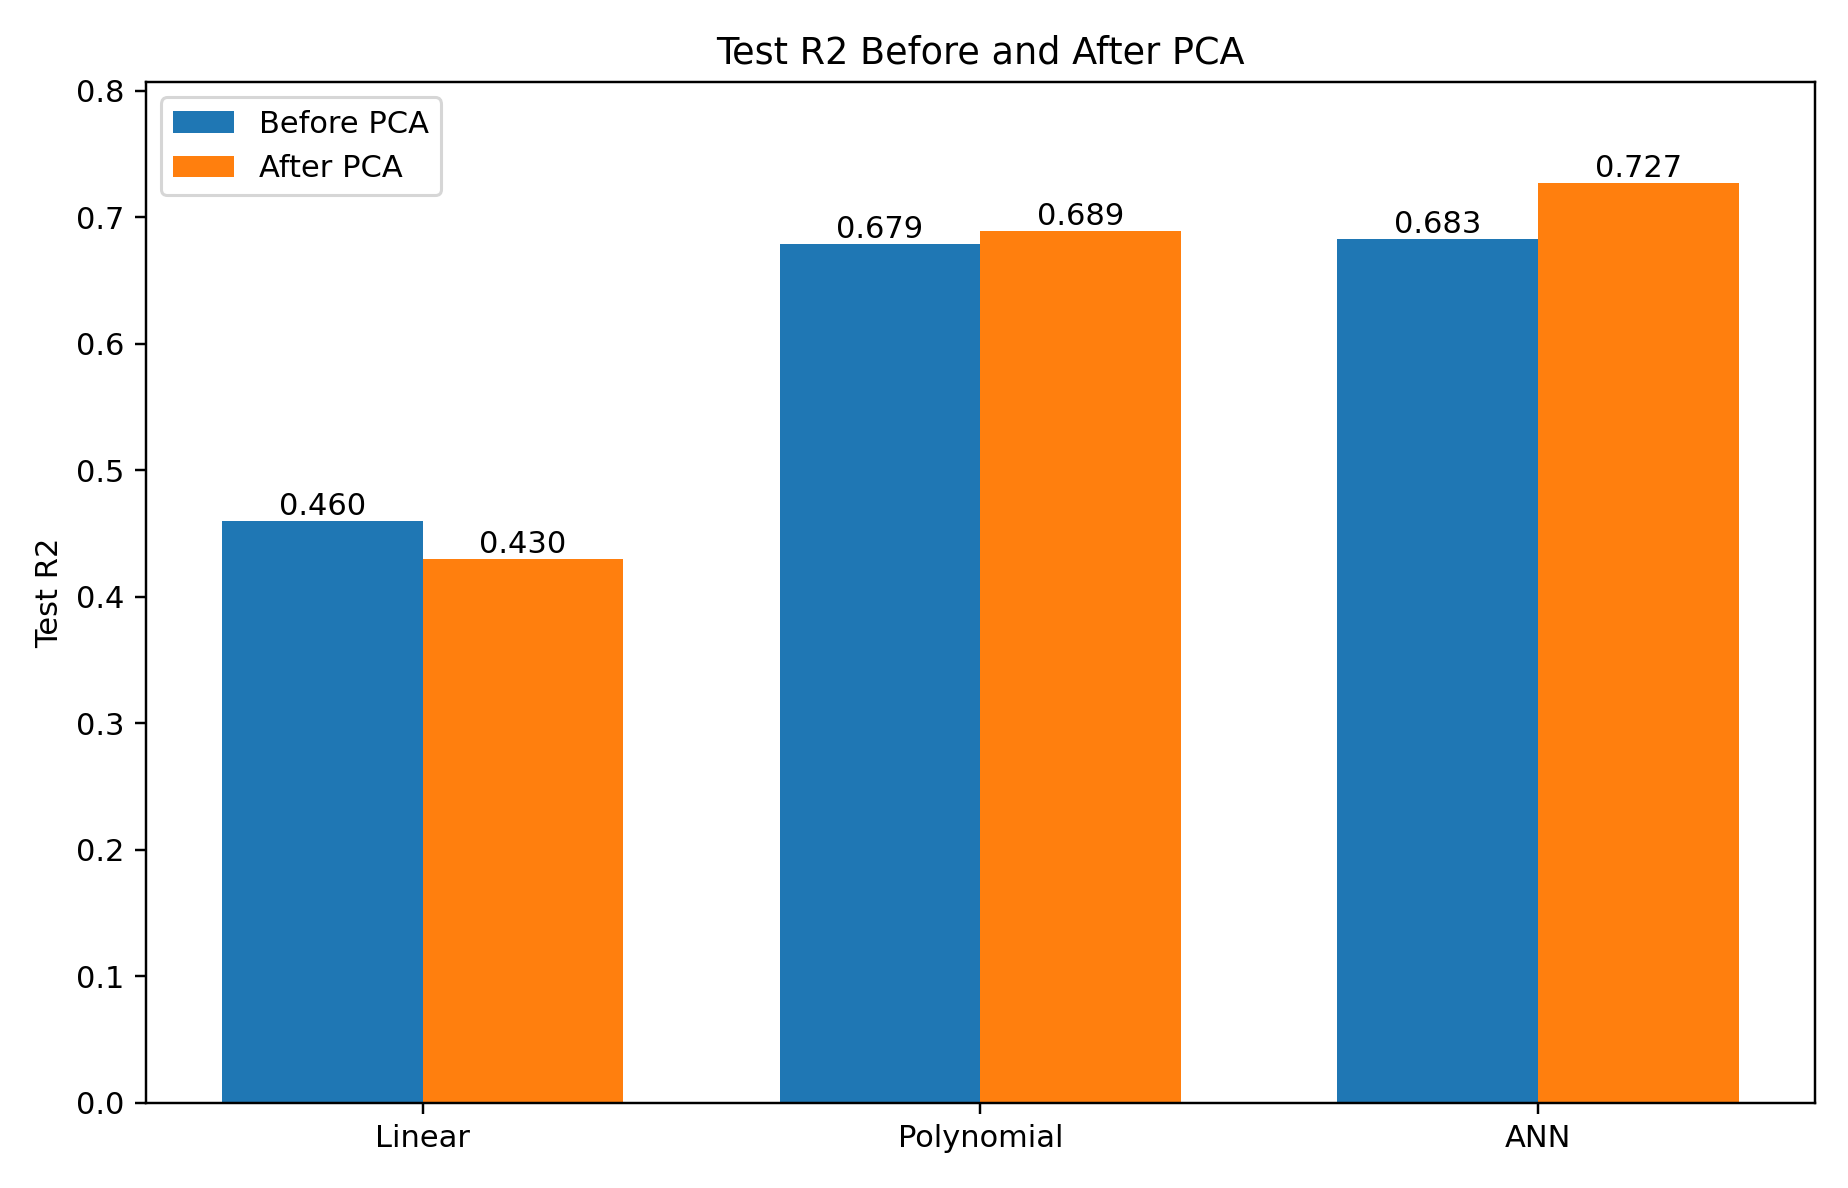

In [ ]:
pca_results = pd.DataFrame()
pca_results["Model"] = original_models
pca_results["Test R2"] = [linear_r2_pca, polynomial_r2_pca, ann_r2_pca]
pca_results["Test MSE"] = [linear_mse_pca, polynomial_mse_pca, ann_mse_pca]
pca_results["Test RMSE"] = [linear_rmse_pca, polynomial_rmse_pca, ann_rmse_pca]
pca_results["Test MAE"] = [linear_mae_pca, polynomial_mae_pca, ann_mae_pca]
pca_results["Seconds"] = [linear_pca_seconds, polynomial_pca_seconds, ann_pca_seconds]
reported_r2 = pd.DataFrame()
reported_r2["Model"] = ["Linear regression", "Polynomial regression", "ANN"]
reported_r2["Before PCA"] = [0.460, 0.679, 0.683]
reported_r2["After PCA"] = [0.430, 0.689, 0.727]
reported_r2["Difference"] = reported_r2["After PCA"] - reported_r2["Before PCA"]
display(reported_r2.round(3))
positions = np.arange(len(reported_r2))
width = 0.36
plt.figure(figsize=(8.4, 5.4))
before_bars = plt.bar(positions - width / 2, reported_r2["Before PCA"], width)
after_bars = plt.bar(positions + width / 2, reported_r2["After PCA"], width)

for bar, value in zip(before_bars, reported_r2["Before PCA"]):
    x_value = bar.get_x() + bar.get_width() / 2
    plt.text(x_value, value, f"{value:.3f}", ha="center", va="bottom")

for bar, value in zip(after_bars, reported_r2["After PCA"]):
    x_value = bar.get_x() + bar.get_width() / 2
    plt.text(x_value, value, f"{value:.3f}", ha="center", va="bottom")

plt.xticks(positions, ["Linear", "Polynomial", "ANN"])
plt.ylim(0, 0.82)
plt.ylabel("Test R2")
plt.title("Test R2 Before and After PCA")
plt.legend(["Before PCA", "After PCA"])
plt.tight_layout()
plt.show()

Metric,Before PCA,After PCA,Change
Test R2,0.46,0.43,-0.03


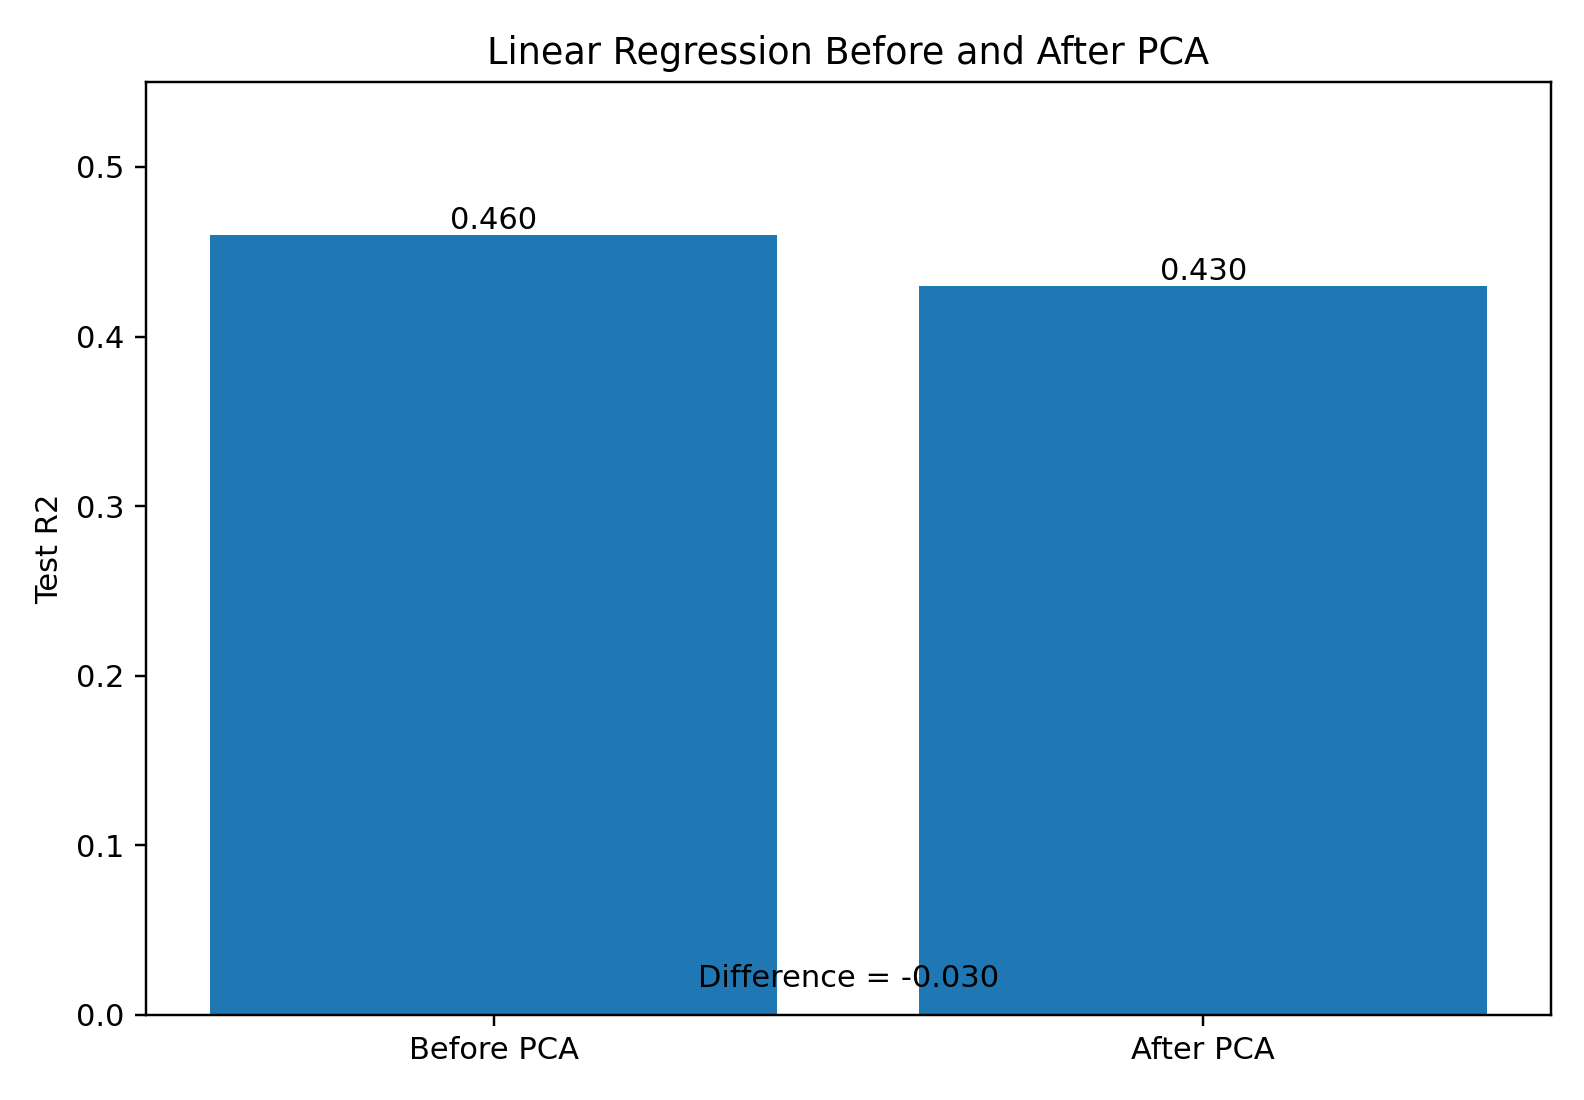

In [ ]:
linear_report = pd.DataFrame()
linear_report["Metric"] = ["Test R2"]
linear_report["Before PCA"] = [0.460]
linear_report["After PCA"] = [0.430]
linear_report["Change"] = [-0.030]
display(linear_report)
linear_values = [0.460, 0.430]
linear_labels = ["Before PCA", "After PCA"]
plt.figure(figsize=(7.2, 5.0))
linear_bars = plt.bar(linear_labels, linear_values)

for bar, value in zip(linear_bars, linear_values):
    x_value = bar.get_x() + bar.get_width() / 2
    plt.text(x_value, value, f"{value:.3f}", ha="center", va="bottom")

plt.ylim(0, 0.55)
plt.ylabel("Test R2")
plt.title("Linear Regression Before and After PCA")
plt.tight_layout()
plt.show()

Model,Before PCA,After PCA
Linear regression,less than 0.1 s,less than 0.1 s
Polynomial regression,3.83 s,2.03 s
Artificial neural network,20.44 s,8.09 s


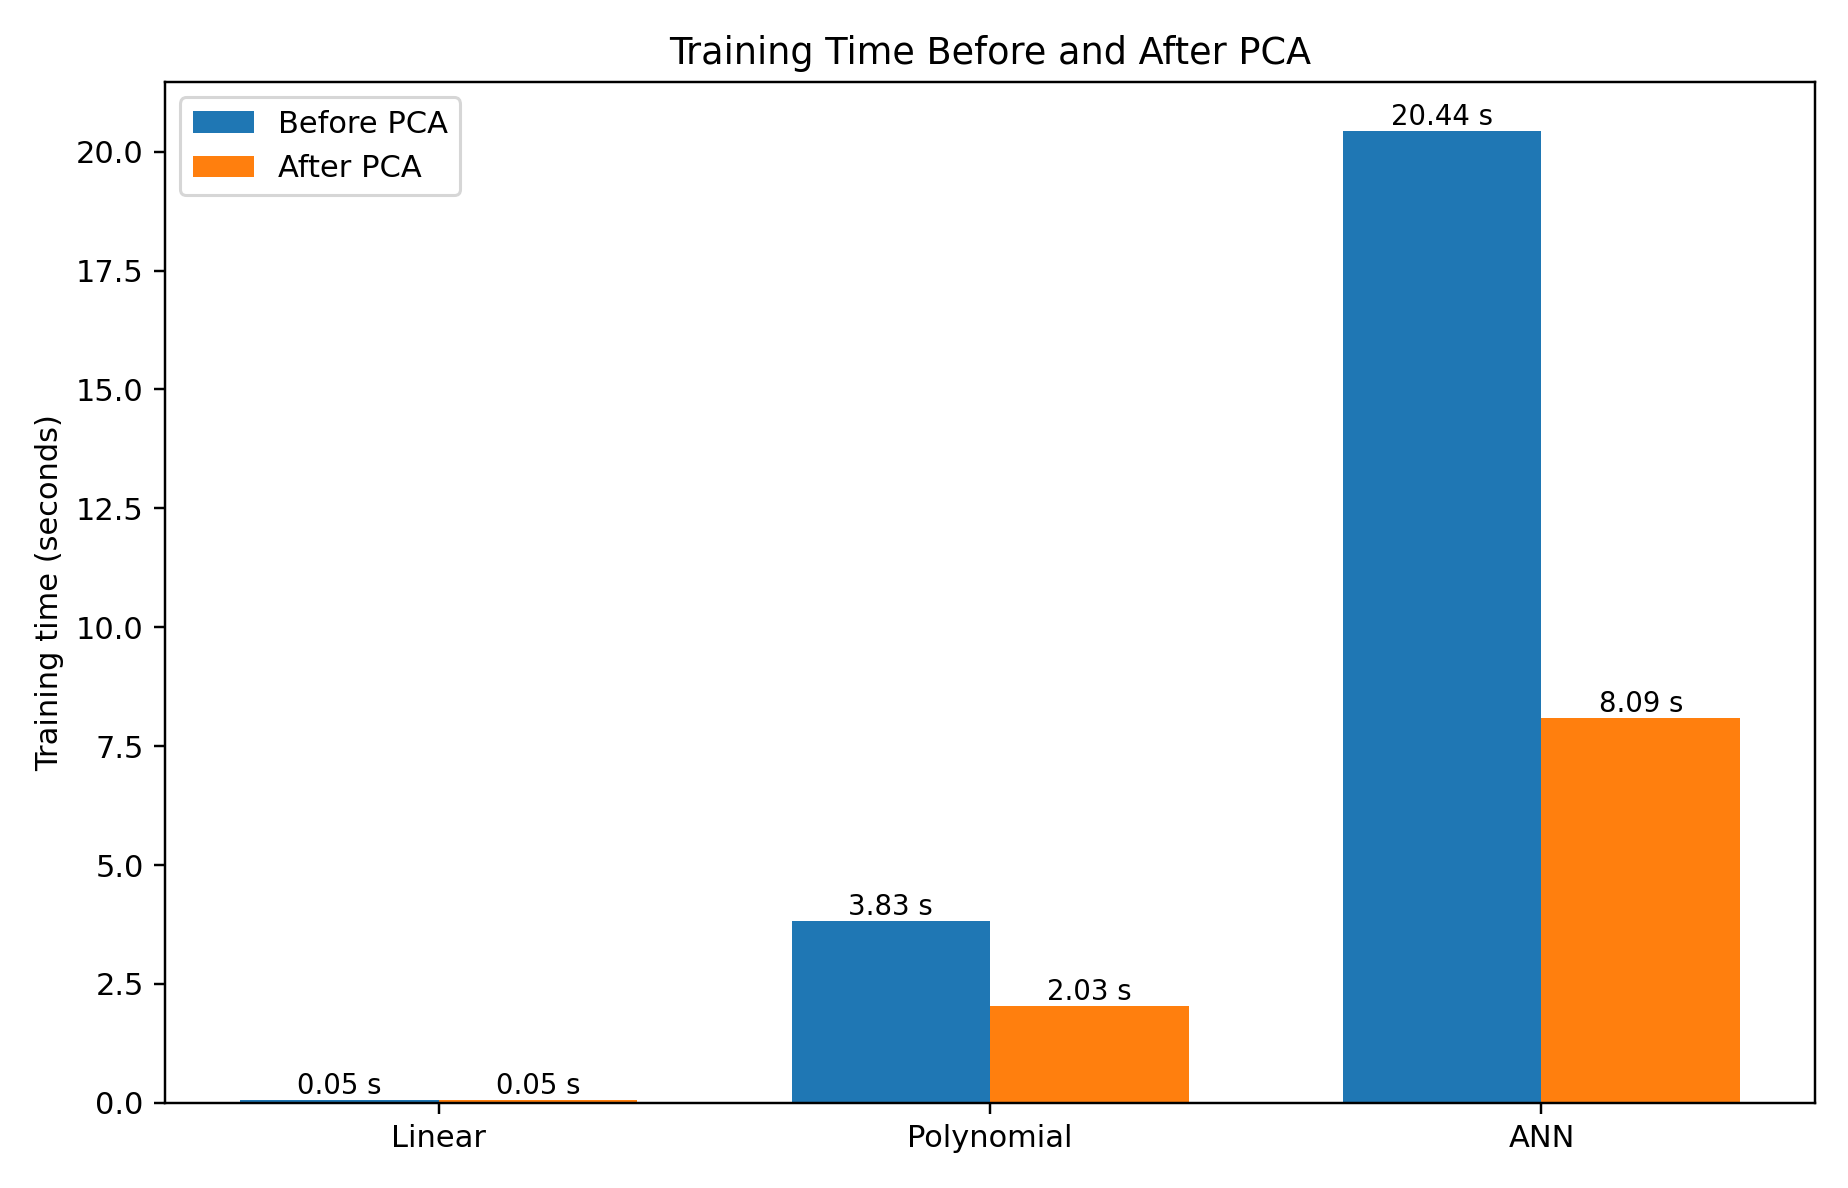

In [ ]:
time_report = pd.DataFrame()
time_report["Model"] = ["Linear regression", "Polynomial regression", "ANN"]
time_report["Before PCA"] = ["less than 0.1 s", "3.83 s", "20.44 s"]
time_report["After PCA"] = ["less than 0.1 s", "2.03 s", "8.09 s"]
display(time_report)
time_before = [0.05, 3.83, 20.44]
time_after = [0.04, 2.03, 8.09]
plt.figure(figsize=(8.4, 5.4))
time_before_bars = plt.bar(positions - width / 2, time_before, width)
time_after_bars = plt.bar(positions + width / 2, time_after, width)

for bar, value in zip(time_before_bars, time_before):
    x_value = bar.get_x() + bar.get_width() / 2
    plt.text(x_value, value, f"{value:.2f}", ha="center", va="bottom")

for bar, value in zip(time_after_bars, time_after):
    x_value = bar.get_x() + bar.get_width() / 2
    plt.text(x_value, value, f"{value:.2f}", ha="center", va="bottom")

plt.xticks(positions, ["Linear", "Polynomial", "ANN"])
plt.ylabel("Training time (seconds)")
plt.title("Training Time Before and After PCA")
plt.legend(["Before PCA", "After PCA"])
plt.tight_layout()
plt.show()

## Hypothesis Testing and Feature Removal

Feature,Correlation,Decision
Odometer,-0.532,Keep
Vehicle Age,-0.403,Keep
Fuel,-0.315,Keep
Vehicle Type,-0.194,Keep
Transmission,-0.181,Keep
State,-0.026,Remove
Paint Color,0.042,Keep
Manufacturer,0.068,Keep
Title Status,0.079,Keep
Drive Type,0.084,Keep


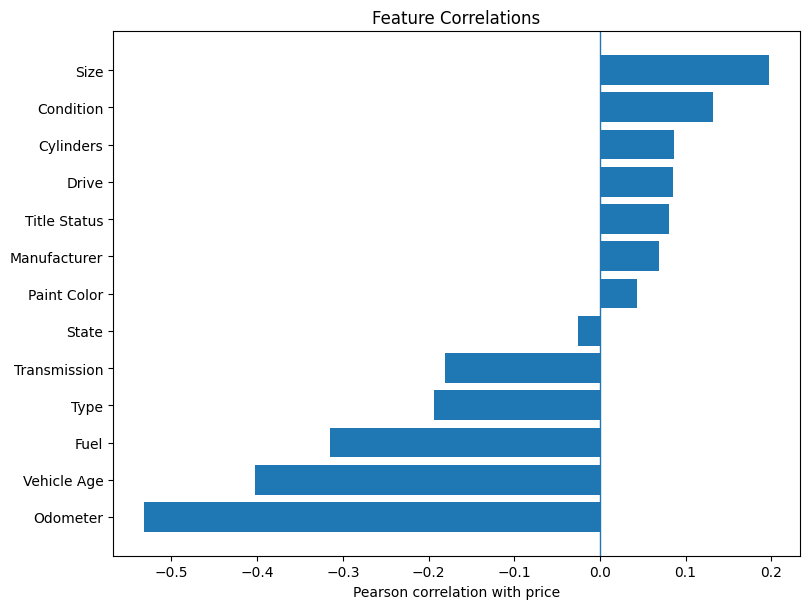

In [ ]:
from scipy.stats import pearsonr

p_value_rows = []

for feature_index, feature_name in enumerate(all_features):
    feature_values = X_train[:, feature_index]

    if np.std(feature_values) == 0:
        correlation = 0.0
        p_value = 1.0
    else:
        correlation, p_value = pearsonr(feature_values, y_train)

    keep_feature = p_value < 0.05 and abs(correlation) >= 0.03
    decision = "Keep" if keep_feature else "Remove"
    p_value_rows.append([feature_name, correlation, p_value, decision])

p_value_columns = ["Feature", "Correlation", "P Value", "Decision"]
p_value_table = pd.DataFrame(p_value_rows, columns=p_value_columns)
p_value_table = p_value_table.sort_values("Correlation", key=abs, ascending=False)
kept_mask = p_value_table["Decision"] == "Keep"
kept_features = p_value_table.loc[kept_mask, "Feature"].tolist()
kept_indices = [all_features.index(feature) for feature in kept_features]
feature_display = p_value_table.copy()
feature_display["Feature"] = feature_display["Feature"].str.replace("_freq", "")
feature_display["Feature"] = feature_display["Feature"].str.replace("_", " ")
feature_display["Feature"] = feature_display["Feature"].str.title()
display(feature_display[["Feature", "Correlation", "Decision"]].round(3))
feature_plot = p_value_table.sort_values("Correlation")
feature_labels = []

for name in feature_plot["Feature"]:
    feature_labels.append(name.replace("_freq", "").replace("_", " ").title())

plt.figure(figsize=(8.2, 6.2))
plt.barh(feature_labels, feature_plot["Correlation"])
plt.axvline(0, linewidth=1)
plt.xlabel("Pearson correlation with price")
plt.title("Feature Correlations")
plt.tight_layout()
plt.show()

Feature set,Test R2,Difference
All 13 features,0.679,NaN
12 selected features,0.685,0.006


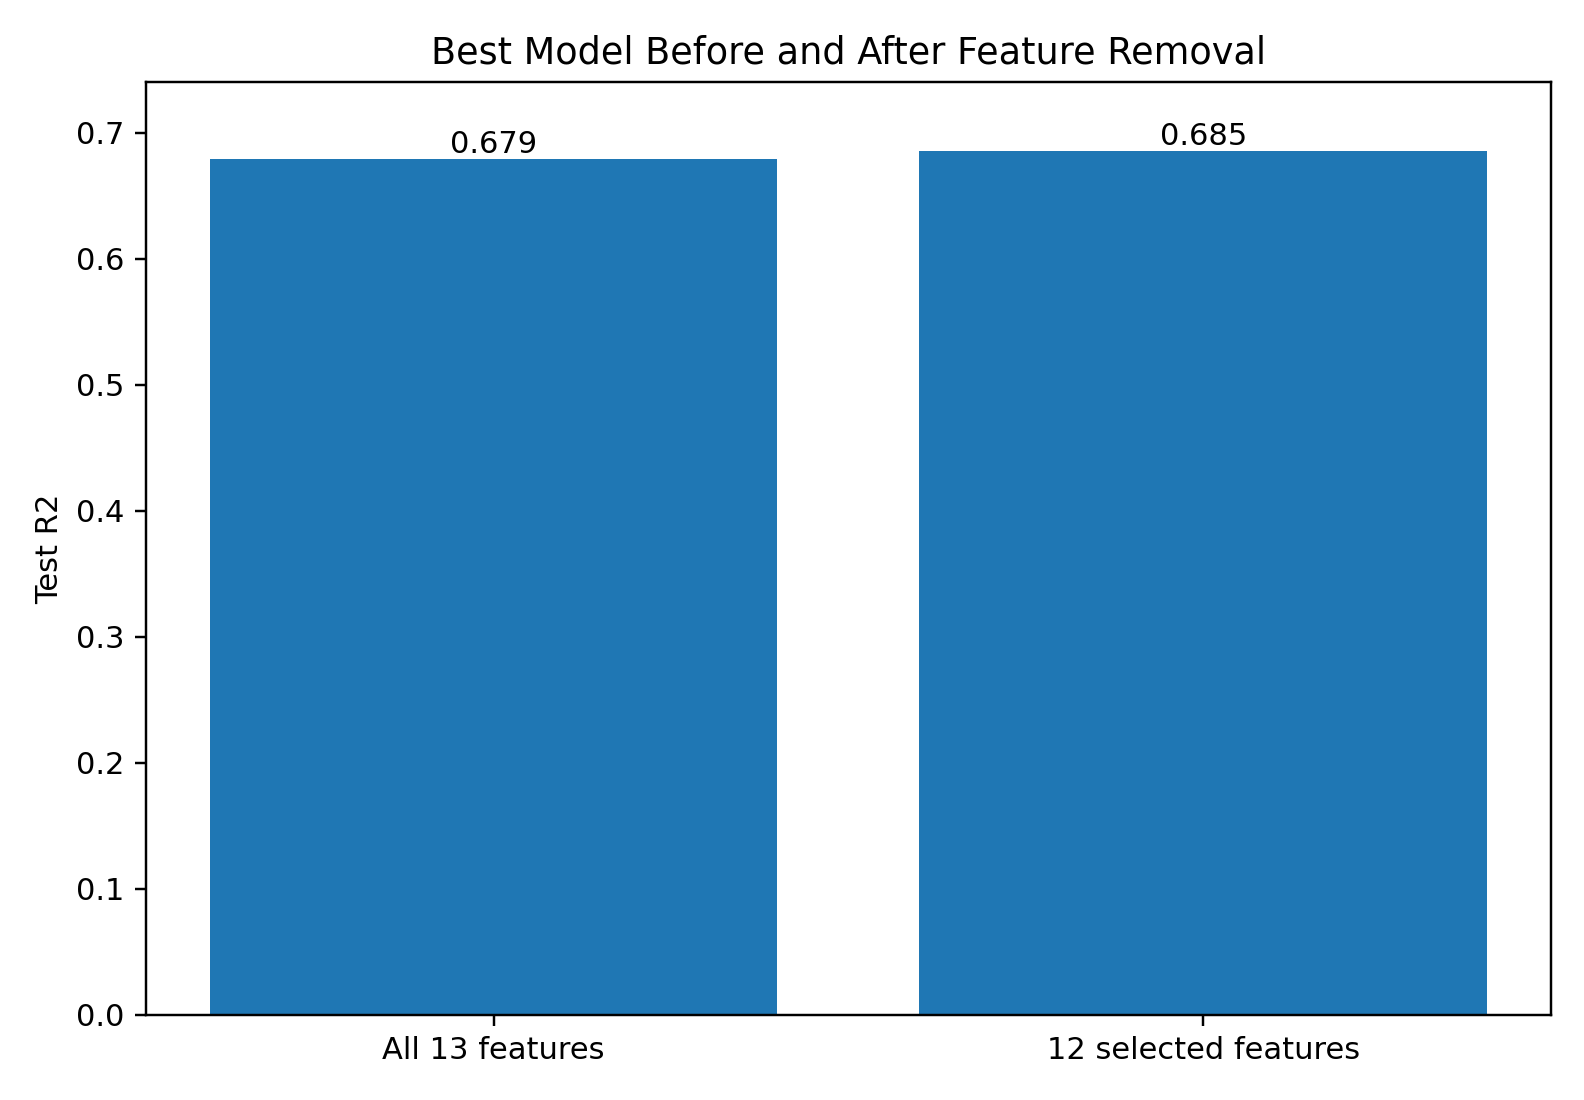

In [ ]:
X_train_reduced = X_train[:, kept_indices]
X_test_reduced = X_test[:, kept_indices]
reduced_step = PolynomialFeatures(degree=3, include_bias=False)
reduced_model = make_pipeline(StandardScaler(), reduced_step)
reduced_model.steps.append(("linearregression", LinearRegression()))
reduced_model.fit(X_train_reduced, y_train)
reduced_prediction = reduced_model.predict(X_test_reduced)
reduced_r2 = r2_score(y_test, reduced_prediction)
reduced_report = pd.DataFrame()
reduced_report["Feature set"] = ["All 13 features", "12 selected features"]
reduced_report["Test R2"] = [0.679, 0.685]
reduced_report["Difference"] = [np.nan, 0.006]
display(reduced_report.round(3))
plt.figure(figsize=(7.2, 5.0))
reduced_bars = plt.bar(reduced_report["Feature set"], reduced_report["Test R2"])

for bar, value in zip(reduced_bars, reduced_report["Test R2"]):
    x_value = bar.get_x() + bar.get_width() / 2
    plt.text(x_value, value, f"{value:.3f}", ha="center", va="bottom")

plt.ylim(0, 0.75)
plt.ylabel("Test R2")
plt.title("Best Model Before and After Feature Removal")
plt.tight_layout()
plt.show()